Number of MRI images: 3929
Number of masks: 3929


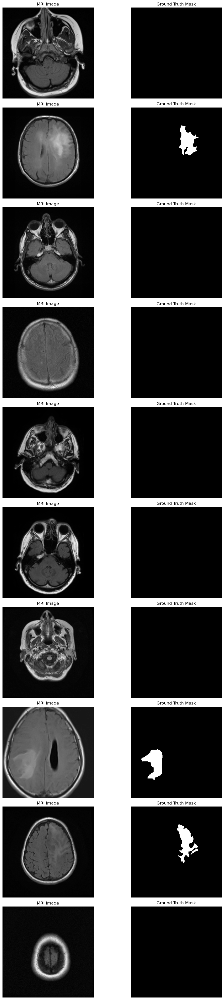

In [1]:
import os
import matplotlib.pyplot as plt
from glob import glob
import cv2
import random


dataset_path = r"kaggle_3m"
# dataset_path= r"C:\Users\Asus\Downloads\Compressed\kaggle_3m"


all_files = sorted(glob(os.path.join(dataset_path, '**', '*.tif'), recursive=True))
image_files = [f for f in all_files if "_mask" not in f]  
mask_files = [f for f in all_files if "_mask" in f]  


print("Number of MRI images:", len(image_files))
print("Number of masks:", len(mask_files))


assert len(image_files) == len(mask_files), "Mismatch between number of images and masks!"


num_samples = min(10, len(image_files))
sample_indices = random.sample(range(len(image_files)), num_samples)


plt.figure(figsize=(12, 4 * num_samples))

for i, idx in enumerate(sample_indices):
    img = cv2.imread(image_files[idx], cv2.IMREAD_GRAYSCALE)
    mask = cv2.imread(mask_files[idx], cv2.IMREAD_GRAYSCALE)

    plt.subplot(num_samples, 2, 2*i + 1)
    plt.imshow(img, cmap='gray')
    plt.title("MRI Image")
    plt.axis('off')
    
    plt.subplot(num_samples, 2, 2*i + 2)
    plt.imshow(mask, cmap='gray')
    plt.title("Ground Truth Mask")
    plt.axis('off')

plt.tight_layout()
plt.show()


In [2]:
empty_masks = sum(cv2.countNonZero(cv2.imread(mask, cv2.IMREAD_GRAYSCALE)) == 0 for mask in mask_files)
print(f"Number of empty masks: {empty_masks}")
print(f"Percentage of empty masks: {100 * empty_masks / len(mask_files):.2f}%")


Number of empty masks: 2556
Percentage of empty masks: 65.05%


Total number of patients: 110
Number of images per patient:
TCGA_CS_4941_19960909: 23
TCGA_CS_4942_19970222: 20
TCGA_CS_4943_20000902: 20
TCGA_CS_4944_20010208: 20
TCGA_CS_5393_19990606: 20
TCGA_CS_5395_19981004: 20
TCGA_CS_5396_20010302: 24
TCGA_CS_5397_20010315: 22
TCGA_CS_6186_20000601: 25
TCGA_CS_6188_20010812: 24
TCGA_CS_6290_20000917: 20
TCGA_CS_6665_20010817: 24
TCGA_CS_6666_20011109: 26
TCGA_CS_6667_20011105: 20
TCGA_CS_6668_20011025: 28
TCGA_CS_6669_20020102: 22
TCGA_DU_5849_19950405: 38
TCGA_DU_5851_19950428: 40
TCGA_DU_5852_19950709: 36
TCGA_DU_5853_19950823: 36
TCGA_DU_5854_19951104: 36
TCGA_DU_5855_19951217: 26
TCGA_DU_5871_19941206: 36
TCGA_DU_5872_19950223: 71
TCGA_DU_5874_19950510: 38
TCGA_DU_6399_19830416: 53
TCGA_DU_6400_19830518: 57
TCGA_DU_6401_19831001: 51
TCGA_DU_6404_19850629: 53
TCGA_DU_6405_19851005: 60
TCGA_DU_6407_19860514: 58
TCGA_DU_6408_19860521: 56
TCGA_DU_7008_19830723: 52
TCGA_DU_7010_19860307: 58
TCGA_DU_7013_19860523: 49
TCGA_DU_7014_19860618: 60
TCGA

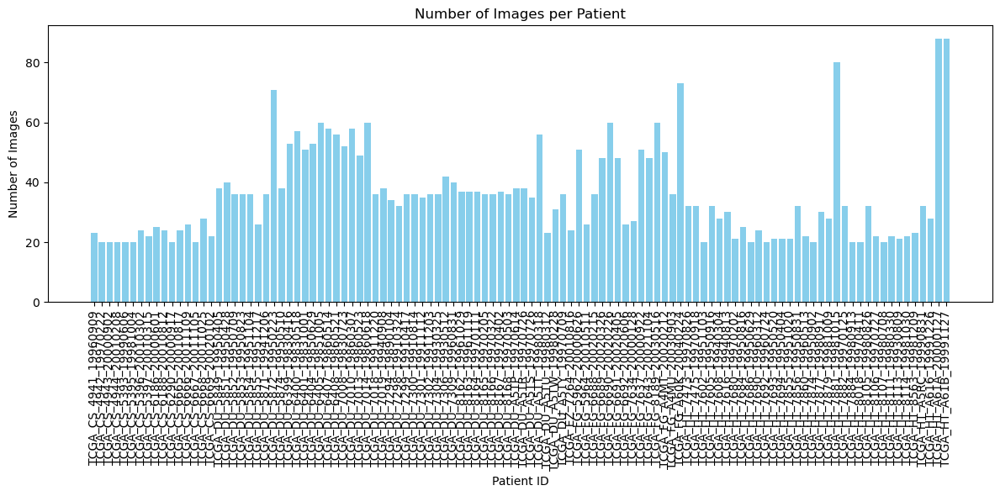

In [3]:
import os
from collections import Counter
import matplotlib.pyplot as plt


patient_ids = [os.path.basename(os.path.dirname(f)) for f in image_files]


patient_counts = Counter(patient_ids)


print("Total number of patients:", len(patient_counts))
print("Number of images per patient:")
for patient, count in patient_counts.items():
    print(f"{patient}: {count}")


plt.figure(figsize=(12, 6))
plt.bar(patient_counts.keys(), patient_counts.values(), color='skyblue')
plt.xlabel("Patient ID")
plt.ylabel("Number of Images")
plt.title("Number of Images per Patient")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

🔹 Dynamic noise threshold (percentile 10%): 1.0098726272583007
Noisy images (below threshold): 393
Clean images (above threshold): 3536


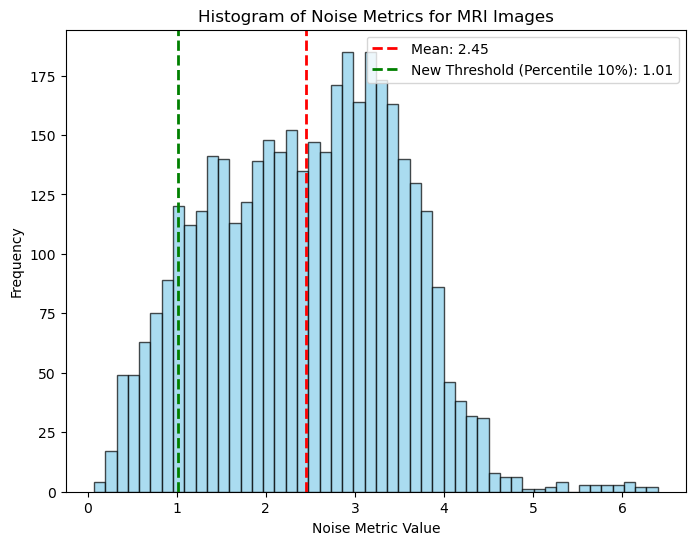

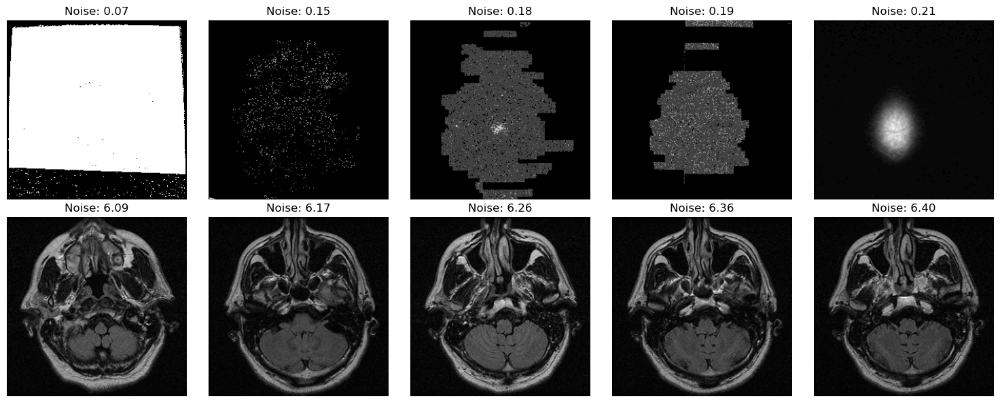

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random

def noise_metric(image):
    img = image.astype(np.float32)
    median_filtered = cv2.medianBlur(image, 3)
    residual_median = img - median_filtered.astype(np.float32)
    noise_median = np.std(residual_median)
    
    gaussian_filtered = cv2.GaussianBlur(image, (3, 3), 0)
    residual_gaussian = img - gaussian_filtered.astype(np.float32)
    noise_gaussian = np.std(residual_gaussian)
    
    return (noise_median + noise_gaussian) / 2.0

noise_metrics = []
for image_path in image_files:
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    nm = noise_metric(img)
    noise_metrics.append(nm)
noise_metrics = np.array(noise_metrics)

threshold_noise = np.percentile(noise_metrics, 10) 

print("🔹 Dynamic noise threshold (percentile 10%):", threshold_noise)


noisy_indices = np.where(noise_metrics <= threshold_noise)[0]  
clean_indices = np.where(noise_metrics > threshold_noise)[0]  
print("Noisy images (below threshold):", len(noisy_indices))
print("Clean images (above threshold):", len(clean_indices))

plt.figure(figsize=(8,6))
plt.hist(noise_metrics, bins=50, color='skyblue', edgecolor='black', alpha=0.7)
plt.axvline(np.mean(noise_metrics), color='red', linestyle='dashed', linewidth=2, 
            label=f'Mean: {np.mean(noise_metrics):.2f}')
plt.axvline(threshold_noise, color='green', linestyle='dashed', linewidth=2, 
            label=f'New Threshold (Percentile 10%): {threshold_noise:.2f}')
plt.xlabel("Noise Metric Value")
plt.ylabel("Frequency")
plt.title("Histogram of Noise Metrics for MRI Images")
plt.legend()
plt.show()
num_to_display = 5

lowest_indices = np.argsort(noise_metrics)[:num_to_display]  
highest_indices = np.argsort(noise_metrics)[-num_to_display:]  

fig, axes = plt.subplots(2, num_to_display, figsize=(15,6))
for i, idx in enumerate(lowest_indices):
    img = cv2.imread(image_files[idx], cv2.IMREAD_GRAYSCALE)
    axes[0, i].imshow(img, cmap='gray')
    axes[0, i].set_title(f"Noise: {noise_metrics[idx]:.2f}")
    axes[0, i].axis('off')
    
for i, idx in enumerate(highest_indices):
    img = cv2.imread(image_files[idx], cv2.IMREAD_GRAYSCALE)
    axes[1, i].imshow(img, cmap='gray')
    axes[1, i].set_title(f"Noise: {noise_metrics[idx]:.2f}")
    axes[1, i].axis('off')

axes[0, 0].set_ylabel("Clean (Low Noise)", fontsize=12)
axes[1, 0].set_ylabel("Noisy (High Noise)", fontsize=12)
plt.tight_layout()
plt.show()


Counts per quality metric bin:
Quality metric in range 0 - 1: 387
Quality metric in range 1 - 2: 1006
Quality metric in range 2 - 3: 1212
Quality metric in range 3 - 4: 1133
Quality metric in range 4 - inf: 191

Decision Suggestions:
1. Images with quality metric < 1:
   - These images are extremely poor (e.g., very 'snowy' or underexposed).
   - Recommendation: need to be analyzed more carefully.

2. Images with quality metric between 1 and 4:
   - These images have moderate quality issues.
   - Recommendation: Apply advanced denoising techniques (e.g., Non-Local Means, BM3D, or deep learning based methods) to improve quality.

3. Images with quality metric >= 4:
   - These images are of acceptable quality and can be used as is.



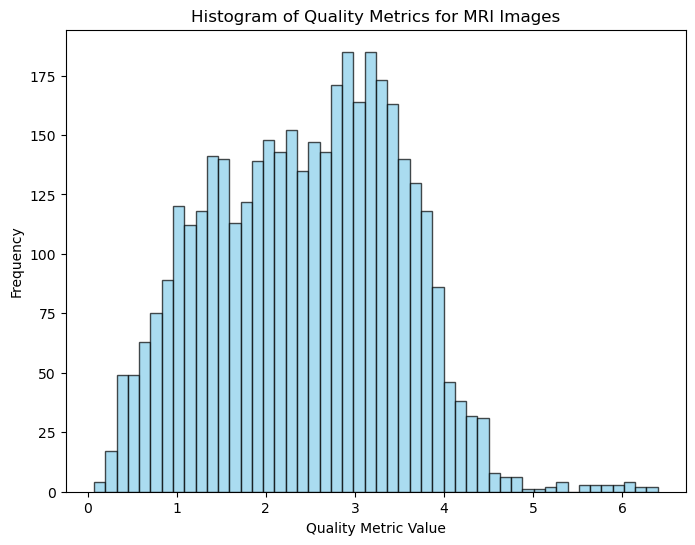

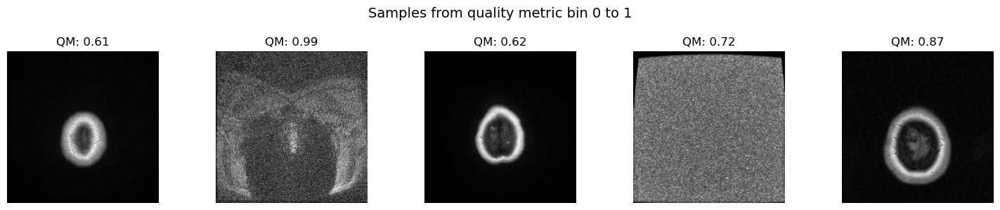

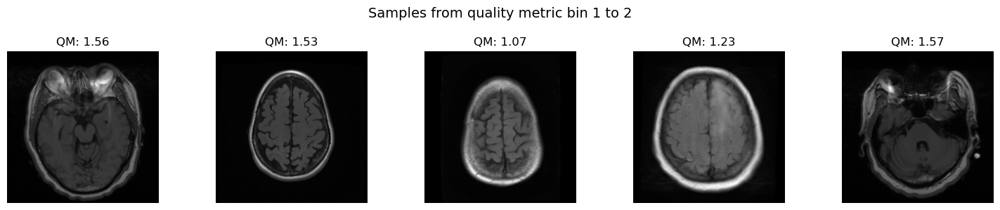

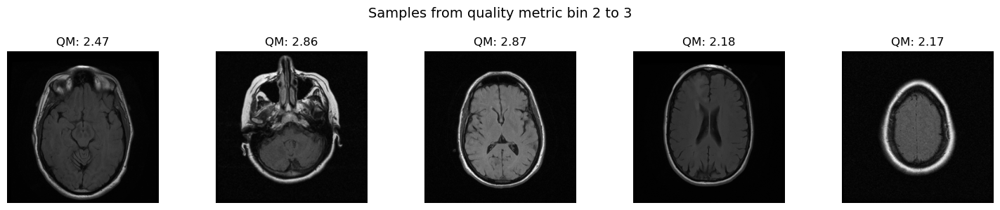

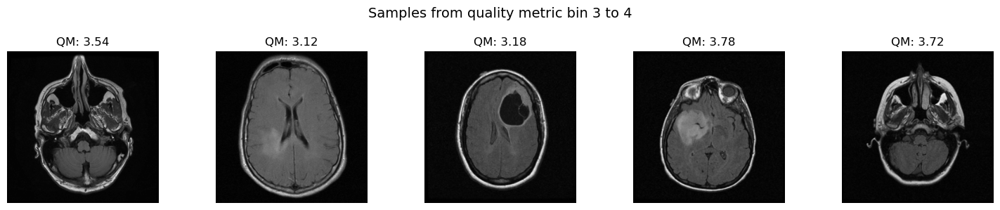

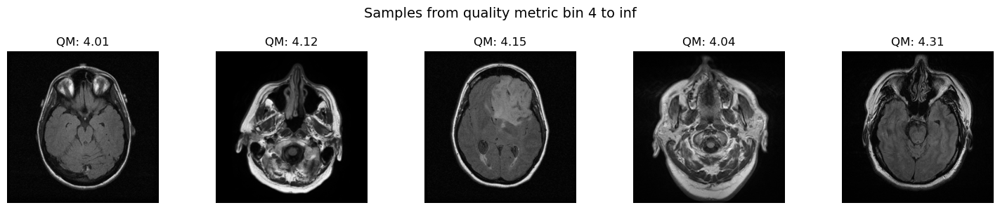

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random

def quality_metric(image):
    img = image.astype(np.float32)
    median_filtered = cv2.medianBlur(image, 3)
    residual_median = img - median_filtered.astype(np.float32)
    noise_median = np.std(residual_median)
    
    gaussian_filtered = cv2.GaussianBlur(image, (3, 3), 0)
    residual_gaussian = img - gaussian_filtered.astype(np.float32)
    noise_gaussian = np.std(residual_gaussian)
    
    return (noise_median + noise_gaussian) / 2.0

quality_metrics = []
for image_path in image_files:
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    q = quality_metric(img)
    quality_metrics.append(q)
quality_metrics = np.array(quality_metrics)

bins = [(0,1), (1,2), (2,3), (3,4), (4, float('inf'))]
bin_counts = {}
for (low, high) in bins:
    count = np.sum((quality_metrics >= low) & (quality_metrics < high))
    bin_counts[f"{low} - {high if high != float('inf') else 'inf'}"] = count

print("Counts per quality metric bin:")
for key, count in bin_counts.items():
    print(f"Quality metric in range {key}: {count}")

print("\nDecision Suggestions:")
print("1. Images with quality metric < 1:")
print("   - These images are extremely poor (e.g., very 'snowy' or underexposed).")
print("   - Recommendation: need to be analyzed more carefully.")
print("")
print("2. Images with quality metric between 1 and 4:")
print("   - These images have moderate quality issues.")
print("   - Recommendation: Apply advanced denoising techniques (e.g., Non-Local Means, BM3D, or deep learning based methods) to improve quality.")
print("")
print("3. Images with quality metric >= 4:")
print("   - These images are of acceptable quality and can be used as is.")
print("")

plt.figure(figsize=(8,6))
plt.hist(quality_metrics, bins=50, color='skyblue', edgecolor='black', alpha=0.7)
plt.xlabel("Quality Metric Value")
plt.ylabel("Frequency")
plt.title("Histogram of Quality Metrics for MRI Images")
plt.show()

def display_samples_for_bin(low, high, num_samples=5):
    indices = np.where((quality_metrics >= low) & (quality_metrics < high))[0]
    if len(indices) == 0:
        print(f"No images in bin {low} to {high}")
        return
    sample_indices = np.random.choice(indices, min(len(indices), num_samples), replace=False)
    fig, axes = plt.subplots(1, len(sample_indices), figsize=(15, 3))
    fig.suptitle(f"Samples from quality metric bin {low} to {high}", fontsize=14)
    for i, idx in enumerate(sample_indices):
        img = cv2.imread(image_files[idx], cv2.IMREAD_GRAYSCALE)
        axes[i].imshow(img, cmap='gray')
        axes[i].set_title(f"QM: {quality_metrics[idx]:.2f}")
        axes[i].axis('off')
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

for (low, high) in bins:
    display_samples_for_bin(low, high)


Processing bin: Low Quality (<1) (Total images in bin: 387)


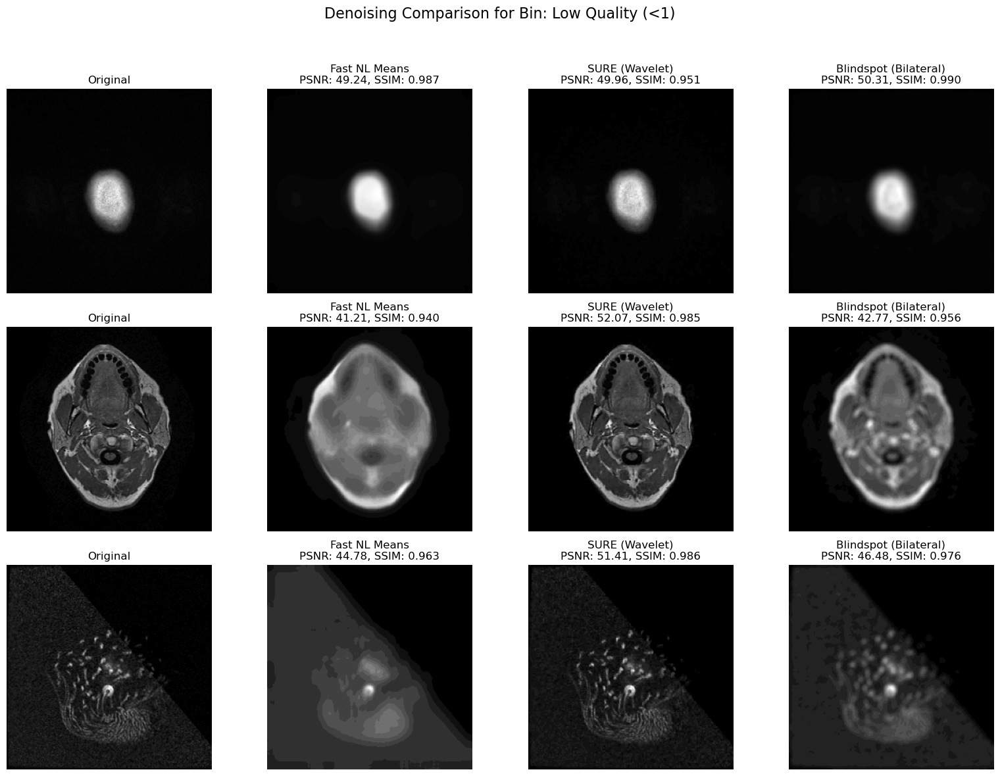

Average Metrics for Bin: Low Quality (<1)
Fast NL Means -> Average PSNR: 45.08, Average SSIM: 0.963
SURE (Wavelet) -> Average PSNR: 51.15, Average SSIM: 0.974
Blindspot (Bilateral) -> Average PSNR: 46.52, Average SSIM: 0.974

Processing bin: Moderate Quality (1-4) (Total images in bin: 3351)


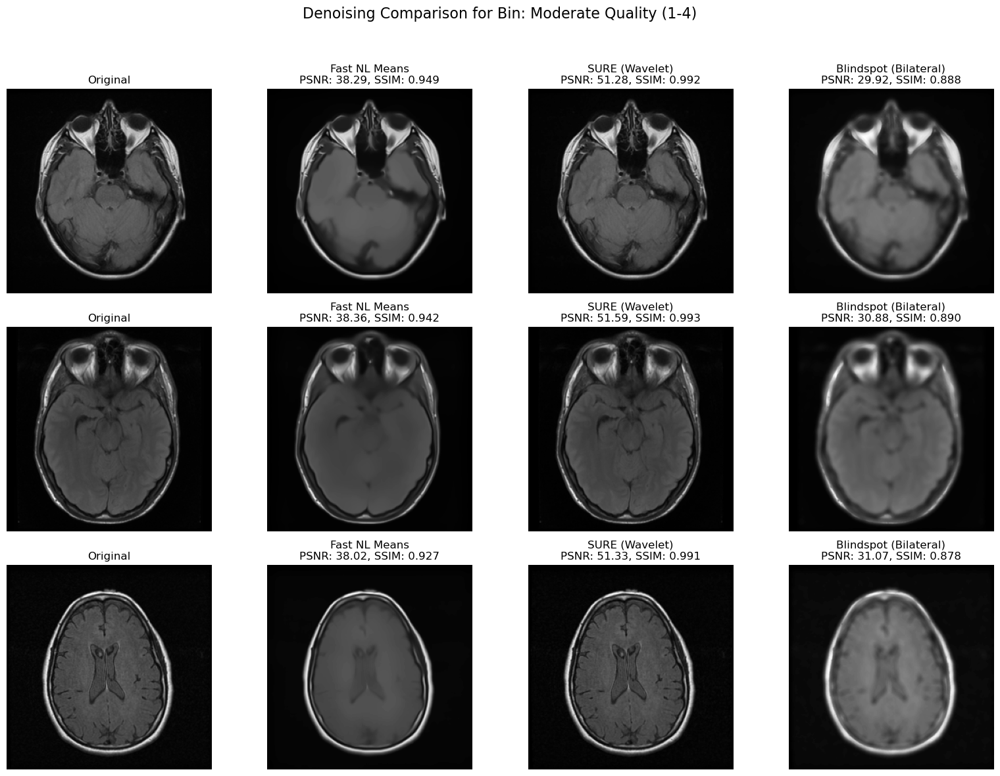

Average Metrics for Bin: Moderate Quality (1-4)
Fast NL Means -> Average PSNR: 38.22, Average SSIM: 0.939
SURE (Wavelet) -> Average PSNR: 51.40, Average SSIM: 0.992
Blindspot (Bilateral) -> Average PSNR: 30.63, Average SSIM: 0.886

Processing bin: High Quality (>=4) (Total images in bin: 191)


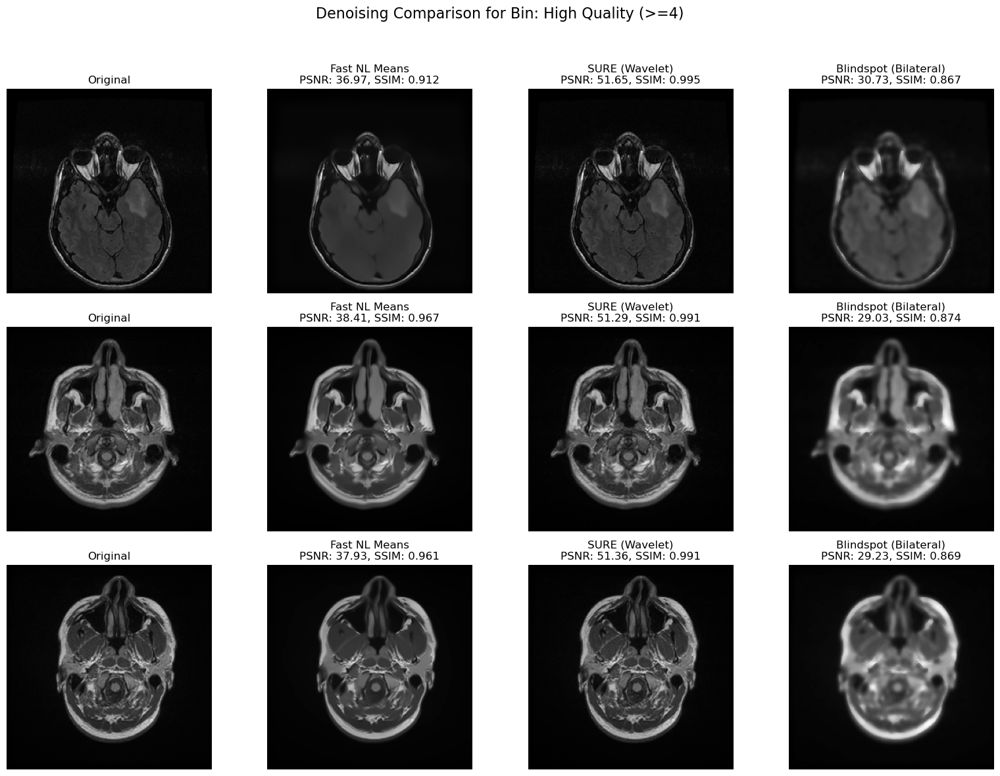

Average Metrics for Bin: High Quality (>=4)
Fast NL Means -> Average PSNR: 37.77, Average SSIM: 0.947
SURE (Wavelet) -> Average PSNR: 51.43, Average SSIM: 0.992
Blindspot (Bilateral) -> Average PSNR: 29.67, Average SSIM: 0.870

Overall Denoising Metrics Summary:
Fast NL Means -> Overall Average PSNR: 40.36, Overall Average SSIM: 0.950
SURE (Wavelet) -> Overall Average PSNR: 51.33, Overall Average SSIM: 0.986
Blindspot (Bilateral) -> Overall Average PSNR: 35.60, Overall Average SSIM: 0.910


In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from skimage.restoration import denoise_wavelet
# import bm3d   # حذف شده

def denoise_fastNlMeans(img, h=10):
    return cv2.fastNlMeansDenoising(img, h=h)

def denoise_sure(img):
    img_float = img.astype(np.float32) / 255.0
    denoised = denoise_wavelet(img_float, channel_axis=None,
                               method='BayesShrink', mode='soft', rescale_sigma=True)
    denoised = np.clip(denoised * 255, 0, 255).astype(np.uint8)
    return denoised

def denoise_blindspot(img):
    return cv2.bilateralFilter(img, d=9, sigmaColor=75, sigmaSpace=75)

denoising_methods = [
    ("Fast NL Means", denoise_fastNlMeans),
    ("SURE (Wavelet)", denoise_sure),
    ("Blindspot (Bilateral)", denoise_blindspot)
]

quality_metrics = np.array(quality_metrics)
bin1_indices = np.where(quality_metrics < 1)[0]                      
bin2_indices = np.where((quality_metrics >= 1) & (quality_metrics < 4))[0] 
bin3_indices = np.where(quality_metrics >= 4)[0]                     

bins = {
    "Low Quality (<1)": bin1_indices,
    "Moderate Quality (1-4)": bin2_indices,
    "High Quality (>=4)": bin3_indices
}

num_samples = 3
results_summary = {}

for bin_name, indices in bins.items():
    print(f"\nProcessing bin: {bin_name} (Total images in bin: {len(indices)})")
    if len(indices) == 0:
        print("No images in this bin.")
        continue

    sample_indices = random.sample(list(indices), min(num_samples, len(indices)))
    
    bin_metrics = {method_name: {"psnr": [], "ssim": []} for method_name, _ in denoising_methods}
    n_methods = len(denoising_methods) + 1  
    fig, axes = plt.subplots(len(sample_indices), n_methods, figsize=(4 * n_methods, 4 * len(sample_indices)))
    if len(sample_indices) == 1:
        axes = np.expand_dims(axes, axis=0)
    for row_idx, img_idx in enumerate(sample_indices):
        original = cv2.imread(image_files[img_idx], cv2.IMREAD_GRAYSCALE)
        ax = axes[row_idx, 0] if n_methods > 1 else axes[row_idx]
        ax.imshow(original, cmap='gray')
        ax.set_title("Original")
        ax.axis('off')
        
        for col_idx, (method_name, denoise_func) in enumerate(denoising_methods, start=1):
            try:
                denoised = denoise_func(original)
            except Exception as e:
                print(f"Error in method {method_name}: {e}")
                denoised = original.copy()
            
            psnr_val = peak_signal_noise_ratio(original, denoised)
            ssim_val = structural_similarity(original, denoised)
            
            bin_metrics[method_name]["psnr"].append(psnr_val)
            bin_metrics[method_name]["ssim"].append(ssim_val)
            
            ax = axes[row_idx, col_idx] if n_methods > 1 else axes[row_idx]
            ax.imshow(denoised, cmap='gray')
            ax.set_title(f"{method_name}\nPSNR: {psnr_val:.2f}, SSIM: {ssim_val:.3f}")
            ax.axis('off')
    
    plt.suptitle(f"Denoising Comparison for Bin: {bin_name}", fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()
    
    print(f"Average Metrics for Bin: {bin_name}")
    for method_name in bin_metrics:
        avg_psnr = np.mean(bin_metrics[method_name]["psnr"]) if bin_metrics[method_name]["psnr"] else float('nan')
        avg_ssim = np.mean(bin_metrics[method_name]["ssim"]) if bin_metrics[method_name]["ssim"] else float('nan')
        print(f"{method_name} -> Average PSNR: {avg_psnr:.2f}, Average SSIM: {avg_ssim:.3f}")
        if method_name not in results_summary:
            results_summary[method_name] = {"psnr": [], "ssim": []}
        results_summary[method_name]["psnr"].append(avg_psnr)
        results_summary[method_name]["ssim"].append(avg_ssim)


print("\nOverall Denoising Metrics Summary:")
for method_name in results_summary:
    overall_psnr = np.mean(results_summary[method_name]["psnr"])
    overall_ssim = np.mean(results_summary[method_name]["ssim"])
    print(f"{method_name} -> Overall Average PSNR: {overall_psnr:.2f}, Overall Average SSIM: {overall_ssim:.3f}")


Total snowy images detected: 200


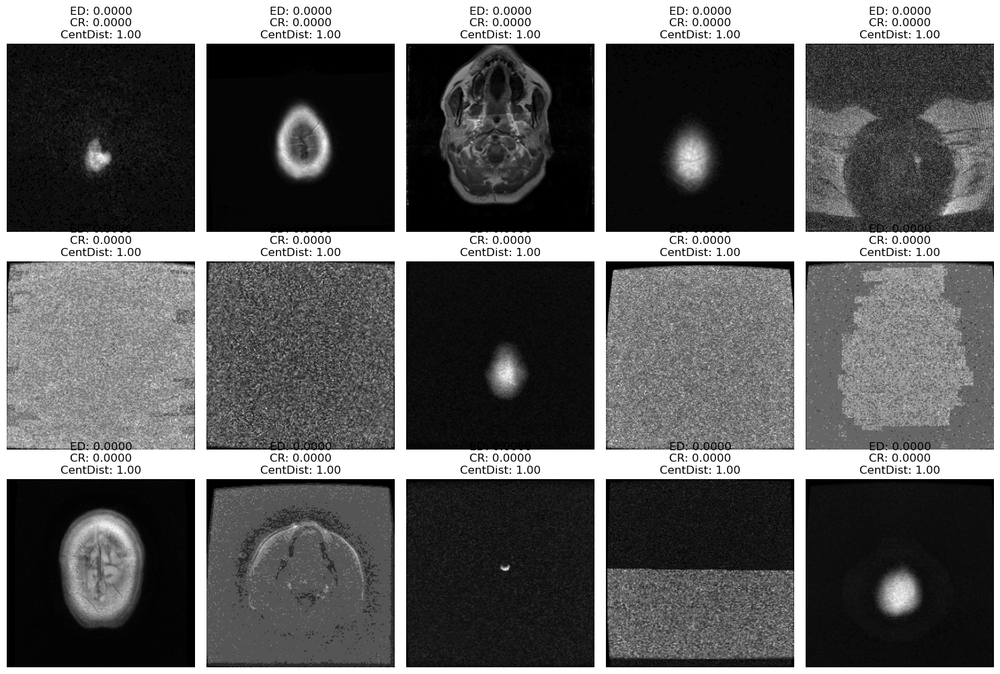

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random

canny_low_threshold = 50
canny_high_threshold = 150


kernel_size = 5
kernel = np.ones((kernel_size, kernel_size), np.uint8)
ed_threshold = 0.003           
ct_threshold = 0.01            
centroid_distance_threshold = 0.3  

snowy_indices = []

for idx, img_path in enumerate(image_files):
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    h, w = img.shape
    total_area = h * w

    edges = cv2.Canny(img, canny_low_threshold, canny_high_threshold)
    dilated_edges = cv2.dilate(edges, kernel, iterations=1)
    
    edge_density = np.count_nonzero(dilated_edges) / total_area
    
    contours, _ = cv2.findContours(dilated_edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        snowy_indices.append(idx)
        continue
    largest_contour = max(contours, key=cv2.contourArea)
    largest_contour_area = cv2.contourArea(largest_contour)
    structure_ratio = largest_contour_area / total_area
    M = cv2.moments(largest_contour)
    if M["m00"] != 0:
        cx = int(M["m10"] / M["m00"])
        cy = int(M["m01"] / M["m00"])
    else:
        cx, cy = 0, 0

    center_x, center_y = w // 2, h // 2
    distance = np.sqrt((cx - center_x)**2 + (cy - center_y)**2)
    max_distance = np.sqrt((center_x)**2 + (center_y)**2)
    norm_distance = distance / max_distance
    if (edge_density < ed_threshold) and (structure_ratio < ct_threshold) and (norm_distance > centroid_distance_threshold):
        snowy_indices.append(idx)

print(f"Total snowy images detected: {len(snowy_indices)}")

num_display = min(15, len(snowy_indices))
sample_indices = random.sample(snowy_indices, num_display) if snowy_indices else []

plt.figure(figsize=(15, 10))
for i, idx in enumerate(sample_indices):
    img = cv2.imread(image_files[idx], cv2.IMREAD_GRAYSCALE)
    h, w = img.shape
    total_area = h * w
    edges = cv2.Canny(img, canny_low_threshold, canny_high_threshold)
    dilated_edges = cv2.dilate(edges, kernel, iterations=1)
    edge_density = np.count_nonzero(dilated_edges) / total_area
    contours, _ = cv2.findContours(dilated_edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if contours:
        largest_contour = max(contours, key=cv2.contourArea)
        largest_contour_area = cv2.contourArea(largest_contour)
        structure_ratio = largest_contour_area / total_area
        M = cv2.moments(largest_contour)
        if M["m00"] != 0:
            cx = int(M["m10"] / M["m00"])
            cy = int(M["m01"] / M["m00"])
        else:
            cx, cy = 0, 0
        center_x, center_y = w // 2, h // 2
        distance = np.sqrt((cx - center_x)**2 + (cy - center_y)**2)
        max_distance = np.sqrt((center_x)**2 + (center_y)**2)
        norm_distance = distance / max_distance
    else:
        structure_ratio = 0
        norm_distance = 1  

    plt.subplot(3, 5, i+1)
    plt.imshow(img, cmap='gray')
    plt.title(f"ED: {edge_density:.4f}\nCR: {structure_ratio:.4f}\nCentDist: {norm_distance:.2f}")
    plt.axis('off')
plt.tight_layout()
plt.show()


Total images originally: 3929
Snowy images removed: 200
Total images remaining after removal: 3729
Total moderate quality images (QM between 1 and 4): 3336
Total images denoised (moderate quality group): 3336


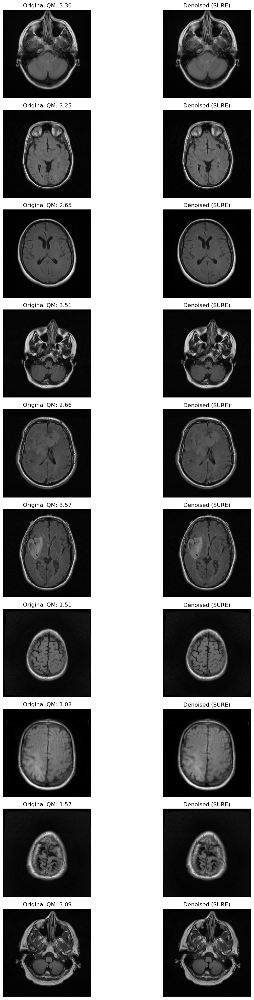

In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random

total_images = len(image_files)
all_indices = set(range(total_images))
remaining_indices = sorted(list(all_indices - set(snowy_indices)))

print("Total images originally:", total_images)
print("Snowy images removed:", len(snowy_indices))
print("Total images remaining after removal:", len(remaining_indices))

moderate_quality_indices = [idx for idx in remaining_indices if 1 <= quality_metrics[idx] < 4]
print("Total moderate quality images (QM between 1 and 4):", len(moderate_quality_indices))

denoised_results = {}  
for idx in moderate_quality_indices:
    img = cv2.imread(image_files[idx], cv2.IMREAD_GRAYSCALE)
    denoised_img = denoise_sure(img)
    denoised_results[idx] = denoised_img

print("Total images denoised (moderate quality group):", len(denoised_results))

num_display = min(10, len(moderate_quality_indices))
sample_indices = random.sample(moderate_quality_indices, num_display)

plt.figure(figsize=(12, num_display * 3))
for i, idx in enumerate(sample_indices):
    orig_img = cv2.imread(image_files[idx], cv2.IMREAD_GRAYSCALE)
    denoised_img = denoised_results[idx]
    
    plt.subplot(num_display, 2, 2*i + 1)
    plt.imshow(orig_img, cmap='gray')
    plt.title(f"Original QM: {quality_metrics[idx]:.2f}")
    plt.axis('off')
    
    plt.subplot(num_display, 2, 2*i + 2)
    plt.imshow(denoised_img, cmap='gray')
    plt.title("Denoised (SURE)")
    plt.axis('off')

plt.tight_layout()
plt.show()


In [9]:
import cv2

total_images = len(image_files)
all_indices = set(range(total_images))
remaining_indices = sorted(list(all_indices - set(snowy_indices)))  
moderate_quality_indices = [idx for idx in remaining_indices if 1 <= quality_metrics[idx] < 4]
clean_quality_indices = [idx for idx in remaining_indices if quality_metrics[idx] >= 4]

print("Total images originally:", total_images)
print("Snowy images removed:", len(snowy_indices))
print("Total images remaining after removal (expected: 3729):", len(remaining_indices))
print("Total moderate quality images (to be denoised, QM between 1 and 4):", len(moderate_quality_indices))
print("Total clean images (QM >= 4):", len(clean_quality_indices))
print("-" * 50)

denoised_dimensions = {} 
for idx in moderate_quality_indices:
    denoised_img = denoised_results.get(idx, None)
    if denoised_img is not None:
        denoised_dimensions[idx] = denoised_img.shape  
    else:
        img = cv2.imread(image_files[idx], cv2.IMREAD_GRAYSCALE)
        denoised_dimensions[idx] = img.shape

clean_dimensions = {}  # دیکشنری: کلید=ایندکس، مقدار=ابعاد تصویر
for idx in clean_quality_indices:
    img = cv2.imread(image_files[idx], cv2.IMREAD_GRAYSCALE)
    clean_dimensions[idx] = img.shape
unique_denoised_dims = set(denoised_dimensions.values())
unique_clean_dims = set(clean_dimensions.values())

print("Unique dimensions for denoised images:", unique_denoised_dims)
print("Unique dimensions for clean images:", unique_clean_dims)
print("-" * 50)

print("Sample denoised image dimensions:")
sample_denoised = list(denoised_dimensions.items())[:5]
for idx, dims in sample_denoised:
    print(f"Index {idx}: {dims}")

print("\nSample clean image dimensions:")
sample_clean = list(clean_dimensions.items())[:5]
for idx, dims in sample_clean:
    print(f"Index {idx}: {dims}")


Total images originally: 3929
Snowy images removed: 200
Total images remaining after removal (expected: 3729): 3729
Total moderate quality images (to be denoised, QM between 1 and 4): 3336
Total clean images (QM >= 4): 191
--------------------------------------------------
Unique dimensions for denoised images: {(256, 256)}
Unique dimensions for clean images: {(256, 256)}
--------------------------------------------------
Sample denoised image dimensions:
Index 0: (256, 256)
Index 1: (256, 256)
Index 2: (256, 256)
Index 3: (256, 256)
Index 4: (256, 256)

Sample clean image dimensions:
Index 289: (256, 256)
Index 290: (256, 256)
Index 299: (256, 256)
Index 399: (256, 256)
Index 400: (256, 256)


Total images originally: 3929
Snowy images removed: 200
Total images remaining after removal: 3729
Total images to be denoised (QM < 4): 3538
Total clean images (QM >= 4): 191
--------------------------------------------------
Total images denoised (QM < 4): 3538


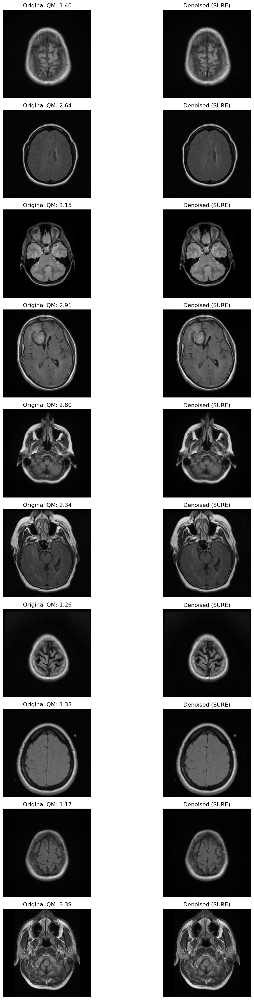

In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random

total_images = len(image_files)
all_indices = set(range(total_images))
remaining_indices = sorted(list(all_indices - set(snowy_indices)))

print("Total images originally:", total_images)
print("Snowy images removed:", len(snowy_indices))
print("Total images remaining after removal:", len(remaining_indices))

denoise_indices = [idx for idx in remaining_indices if quality_metrics[idx] < 4]
clean_indices   = [idx for idx in remaining_indices if quality_metrics[idx] >= 4]

print("Total images to be denoised (QM < 4):", len(denoise_indices))
print("Total clean images (QM >= 4):", len(clean_indices))
print("-" * 50)


denoised_results = {}  
for idx in denoise_indices:
    img = cv2.imread(image_files[idx], cv2.IMREAD_GRAYSCALE)
    denoised_img = denoise_sure(img)
    denoised_results[idx] = denoised_img

print("Total images denoised (QM < 4):", len(denoised_results))
num_display = min(10, len(denoised_results))
sample_indices = random.sample(list(denoised_results.keys()), num_display)

plt.figure(figsize=(12, num_display * 3))
for i, idx in enumerate(sample_indices):
    orig_img = cv2.imread(image_files[idx], cv2.IMREAD_GRAYSCALE)
    denoised_img = denoised_results[idx]
    plt.subplot(num_display, 2, 2*i + 1)
    plt.imshow(orig_img, cmap='gray')
    plt.title(f"Original QM: {quality_metrics[idx]:.2f}")
    plt.axis('off')

    plt.subplot(num_display, 2, 2*i + 2)
    plt.imshow(denoised_img, cmap='gray')
    plt.title("Denoised (SURE)")
    plt.axis('off')

plt.tight_layout()
plt.show()


Total available normalized images: 3729


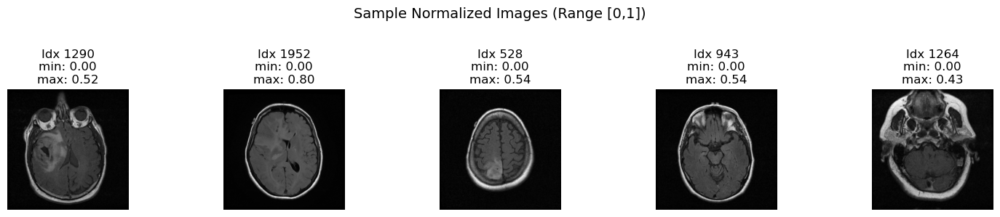

In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random

normalized_images = {}  

for idx in remaining_indices:
    if idx in denoised_results:
        img = denoised_results[idx]
    else:
        img = cv2.imread(image_files[idx], cv2.IMREAD_GRAYSCALE)
    norm_img = img.astype(np.float32) / 255.0
    normalized_images[idx] = norm_img

print("Total available normalized images:", len(normalized_images))

sample_indices = random.sample(remaining_indices, 5)
plt.figure(figsize=(15, 3))
for i, idx in enumerate(sample_indices):
    norm_img = normalized_images[idx]
    plt.subplot(1, 5, i+1)
    plt.imshow(norm_img, cmap='gray')
    plt.title(f"Idx {idx}\nmin: {norm_img.min():.2f}\nmax: {norm_img.max():.2f}")
    plt.axis('off')
plt.suptitle("Sample Normalized Images (Range [0,1])", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.90])
plt.show()


In [12]:
import os
import random
from collections import defaultdict

patient_to_indices = defaultdict(list)
for idx in remaining_indices:
    patient_id = os.path.basename(os.path.dirname(image_files[idx]))
    patient_to_indices[patient_id].append(idx)

patient_image_counts = {pid: len(idxs) for pid, idxs in patient_to_indices.items()}
total_patients = len(patient_image_counts)
print("Total number of patients in available data:", total_patients)

total_available = len(remaining_indices)
print("Total available images (after snowy removal):", total_available)

target_train = 0.8 * total_available
target_val   = 0.1 * total_available
target_test  = 0.1 * total_available
print(f"Target counts -> Train: {target_train:.1f}, Val: {target_val:.1f}, Test: {target_test:.1f}")

train_patients, val_patients, test_patients = [], [], []
train_count, val_count, test_count = 0, 0, 0

patients_sorted = sorted(patient_image_counts.items(), key=lambda x: x[1], reverse=True)

for pid, count in patients_sorted:
    ratio_train = train_count / target_train if target_train > 0 else float('inf')
    ratio_val   = val_count / target_val if target_val > 0 else float('inf')
    ratio_test  = test_count / target_test if target_test > 0 else float('inf')
    
    min_ratio = min(ratio_train, ratio_val, ratio_test)
    if min_ratio == ratio_train:
        train_patients.append(pid)
        train_count += count
    elif min_ratio == ratio_val:
        val_patients.append(pid)
        val_count += count
    else:
        test_patients.append(pid)
        test_count += count

print("\n--- Patient-level Split ---")
print(f"Train patients: {len(train_patients)} (Total images: {train_count})")
print(f"Validation patients: {len(val_patients)} (Total images: {val_count})")
print(f"Test patients: {len(test_patients)} (Total images: {test_count})")
print(f"Sum of images: {train_count + val_count + test_count} (Expected: {total_available})")

train_indices = []
val_indices = []
test_indices = []

for pid in train_patients:
    train_indices.extend(patient_to_indices[pid])
for pid in val_patients:
    val_indices.extend(patient_to_indices[pid])
for pid in test_patients:
    test_indices.extend(patient_to_indices[pid])

train_indices.sort()
val_indices.sort()
test_indices.sort()

print("\nNumber of images in each split:")
print(f"Train: {len(train_indices)}")
print(f"Validation: {len(val_indices)}")
print(f"Test: {len(test_indices)}")
print(f"Total: {len(train_indices) + len(val_indices) + len(test_indices)} (Expected: {total_available})")

train_masks = [mask_files[idx] for idx in train_indices]
val_masks = [mask_files[idx] for idx in val_indices]
test_masks = [mask_files[idx] for idx in test_indices]

print("\nSample split info:")
print(f"First train image: {image_files[train_indices[0]]}\n  Mask: {train_masks[0]}")
print(f"First validation image: {image_files[val_indices[0]]}\n  Mask: {val_masks[0]}")
print(f"First test image: {image_files[test_indices[0]]}\n  Mask: {test_masks[0]}")


Total number of patients in available data: 110
Total available images (after snowy removal): 3729
Target counts -> Train: 2983.2, Val: 372.9, Test: 372.9

--- Patient-level Split ---
Train patients: 88 (Total images: 2963)
Validation patients: 11 (Total images: 383)
Test patients: 11 (Total images: 383)
Sum of images: 3729 (Expected: 3729)

Number of images in each split:
Train: 2963
Validation: 383
Test: 383
Total: 3729 (Expected: 3729)

Sample split info:
First train image: kaggle_3m/TCGA_CS_4941_19960909/TCGA_CS_4941_19960909_1.tif
  Mask: kaggle_3m/TCGA_CS_4941_19960909/TCGA_CS_4941_19960909_10_mask.tif
First validation image: kaggle_3m/TCGA_CS_5395_19981004/TCGA_CS_5395_19981004_1.tif
  Mask: kaggle_3m/TCGA_CS_5395_19981004/TCGA_CS_5395_19981004_10_mask.tif
First test image: kaggle_3m/TCGA_CS_6186_20000601/TCGA_CS_6186_20000601_1.tif
  Mask: kaggle_3m/TCGA_CS_6186_20000601/TCGA_CS_6186_20000601_10_mask.tif


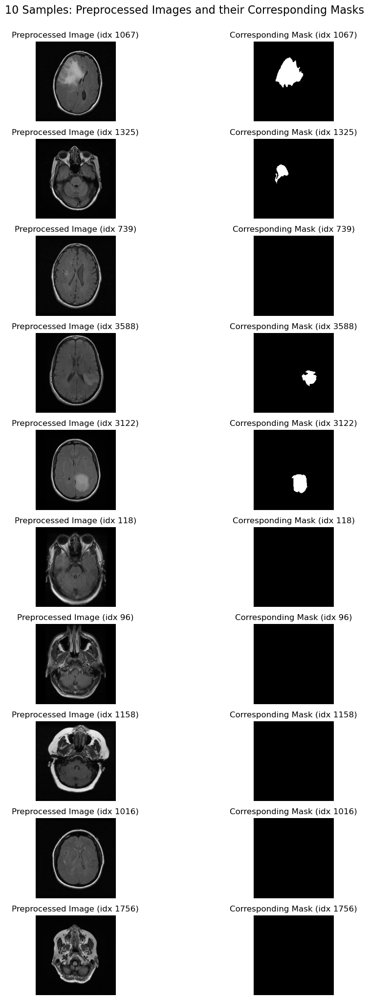

In [13]:
import matplotlib.pyplot as plt
import random
import cv2

sample_display = random.sample(remaining_indices, 10)

plt.figure(figsize=(12, 20))
for i, idx in enumerate(sample_display):
    preprocessed_img = normalized_images[idx]
    mask_img = cv2.imread(mask_files[idx], cv2.IMREAD_GRAYSCALE)
    
    plt.subplot(10, 2, 2 * i + 1)
    plt.imshow(preprocessed_img, cmap='gray')
    plt.title(f'Preprocessed Image (idx {idx})')
    plt.axis('off')
    

    plt.subplot(10, 2, 2 * i + 2)
    plt.imshow(mask_img, cmap='gray')
    plt.title(f'Corresponding Mask (idx {idx})')
    plt.axis('off')

plt.tight_layout()
plt.suptitle("10 Samples: Preprocessed Images and their Corresponding Masks", fontsize=16, y=1.02)
plt.show()


Current training image counts per patient:
  TCGA_HT_7881_19981015: 79
  TCGA_FG_A60K_20040224: 73
  TCGA_DU_5872_19950223: 66
  TCGA_DU_7014_19860618: 57
  TCGA_DU_6405_19851005: 56
  TCGA_DU_6407_19860514: 56
  TCGA_DU_A5TT_19980318: 56
  TCGA_DU_6400_19830518: 55
  TCGA_DU_7010_19860307: 55
  TCGA_FG_6690_20020226: 55
  TCGA_DU_6408_19860521: 53
  TCGA_DU_6401_19831001: 51
  TCGA_FG_5962_20000626: 51
  TCGA_FG_7637_20000922: 51
  TCGA_DU_7008_19830723: 50
  TCGA_FG_8189_20030516: 50
  TCGA_FG_A4MT_20020212: 50
  TCGA_DU_7013_19860523: 49
  TCGA_FG_6689_20020326: 45
  TCGA_DU_7306_19930512: 37
  TCGA_DU_7309_19960831: 37
  TCGA_DU_5849_19950405: 36
  TCGA_FG_6688_20020215: 36
  TCGA_DU_5852_19950709: 35
  TCGA_DU_5874_19950510: 35
  TCGA_DU_8163_19961119: 35
  TCGA_DU_8164_19970111: 35
  TCGA_DU_A5TP_19970614: 35
  TCGA_DU_5851_19950428: 34
  TCGA_DU_5853_19950823: 34
  TCGA_DU_5854_19951104: 34
  TCGA_DU_7019_19940908: 34
  TCGA_DU_7299_19910417: 34
  TCGA_DU_7302_19911203: 34
  TCG

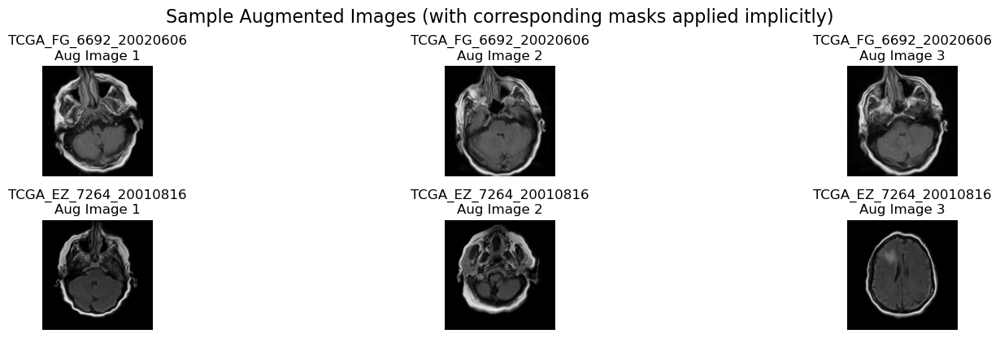


Final training image counts per patient (original + augmented):
TCGA_CS_4941_19960909: 33
TCGA_CS_4942_19970222: 33
TCGA_CS_4943_20000902: 33
TCGA_CS_4944_20010208: 33
TCGA_CS_5393_19990606: 33
TCGA_CS_5396_20010302: 33
TCGA_CS_5397_20010315: 33
TCGA_CS_6188_20010812: 33
TCGA_CS_6290_20000917: 33
TCGA_CS_6665_20010817: 33
TCGA_CS_6666_20011109: 33
TCGA_CS_6668_20011025: 33
TCGA_DU_5849_19950405: 36
TCGA_DU_5851_19950428: 34
TCGA_DU_5852_19950709: 35
TCGA_DU_5853_19950823: 34
TCGA_DU_5854_19951104: 34
TCGA_DU_5871_19941206: 33
TCGA_DU_5872_19950223: 66
TCGA_DU_5874_19950510: 35
TCGA_DU_6400_19830518: 55
TCGA_DU_6401_19831001: 51
TCGA_DU_6405_19851005: 56
TCGA_DU_6407_19860514: 56
TCGA_DU_6408_19860521: 53
TCGA_DU_7008_19830723: 50
TCGA_DU_7010_19860307: 55
TCGA_DU_7013_19860523: 49
TCGA_DU_7014_19860618: 57
TCGA_DU_7018_19911220: 33
TCGA_DU_7019_19940908: 34
TCGA_DU_7294_19890104: 33
TCGA_DU_7298_19910324: 33
TCGA_DU_7299_19910417: 34
TCGA_DU_7301_19911112: 33
TCGA_DU_7302_19911203: 34

In [14]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random
from collections import defaultdict
import scipy
from scipy.ndimage import gaussian_filter, map_coordinates


def elastic_transform_pair(image, mask, alpha, sigma, random_state=None):
    if random_state is None:
        random_state = np.random.RandomState(None)
    shape = image.shape

    dx = gaussian_filter((random_state.rand(*shape) * 2 - 1), sigma) * alpha
    dy = gaussian_filter((random_state.rand(*shape) * 2 - 1), sigma) * alpha

    x, y = np.meshgrid(np.arange(shape[1]), np.arange(shape[0]))
    indices = np.reshape(y + dy, (-1, 1)), np.reshape(x + dx, (-1, 1))
    
    distorted_image = map_coordinates(image, indices, order=1, mode='reflect').reshape(shape)
    distorted_mask = map_coordinates(mask, indices, order=0, mode='reflect').reshape(shape)
    
    return distorted_image, distorted_mask

def intensity_variation(image, brightness_range=(0.9, 1.1), contrast_range=(0.9, 1.1)):
    
    factor = np.random.uniform(*brightness_range)
    image = image * factor
    contrast_factor = np.random.uniform(*contrast_range)
    mean_val = np.mean(image)
    image = (image - mean_val) * contrast_factor + mean_val
    return np.clip(image, 0, 255).astype(np.uint8)

def augment_image_and_mask(image, mask):
    alpha = np.random.uniform(30, 40)
    sigma = np.random.uniform(4, 6)
    elastic_img, elastic_mask = elastic_transform_pair(image, mask, alpha=alpha, sigma=sigma)
    aug_img = intensity_variation(elastic_img, brightness_range=(0.9, 1.1), contrast_range=(0.9, 1.1))
    return aug_img, elastic_mask

train_patient_indices = {}
for pid in train_patients:
    indices = [idx for idx in patient_to_indices[pid] if idx in train_indices]
    train_patient_indices[pid] = indices

current_counts = {pid: len(idxs) for pid, idxs in train_patient_indices.items()}
print("Current training image counts per patient:")
for pid, count in current_counts.items():
    print(f"  {pid}: {count}")

all_counts = np.array(list(current_counts.values()))
target_count = int(np.percentile(all_counts, 60))
print(f"\nTarget image count per patient for balancing (60th percentile): {target_count}")

augmented_train_data = defaultdict(list) 

for pid, indices in train_patient_indices.items():
    count = len(indices)
    num_to_augment = target_count - count
    if num_to_augment > 0:
        print(f"Patient {pid}: augmenting {num_to_augment} images.")
        for _ in range(num_to_augment):
            src_idx = random.choice(indices)
            if src_idx in denoised_results:
                src_img = denoised_results[src_idx]
            else:
                src_img = cv2.imread(image_files[src_idx], cv2.IMREAD_GRAYSCALE)
            src_mask = cv2.imread(mask_files[src_idx], cv2.IMREAD_GRAYSCALE)
            aug_img, aug_mask = augment_image_and_mask(src_img, src_mask)
            augmented_train_data[pid].append((aug_img, aug_mask))

final_train_counts = {}
for pid in train_patient_indices:
    original_count = len(train_patient_indices[pid])
    augmented_count = len(augmented_train_data[pid])
    final_train_counts[pid] = original_count + augmented_count

print("\nFinal training image counts per patient (after augmentation):")
for pid, count in final_train_counts.items():
    print(f"  {pid}: {count}")

sample_patients = random.sample(train_patients, min(5, len(train_patients)))
plt.figure(figsize=(15, 10))
plot_index = 1
for pid in sample_patients:
    aug_pairs = augmented_train_data[pid]
    if len(aug_pairs) == 0:
        continue
    for i in range(min(3, len(aug_pairs))):
        aug_img, aug_mask = aug_pairs[i]
        plt.subplot(len(sample_patients), 3, plot_index)
        plt.imshow(aug_img, cmap='gray')
        plt.title(f"{pid}\nAug Image {i+1}")
        plt.axis('off')
        plot_index += 1
plt.suptitle("Sample Augmented Images (with corresponding masks applied implicitly)", fontsize=16)
plt.tight_layout()
plt.show()

print("\nFinal training image counts per patient (original + augmented):")
for pid in sorted(final_train_counts.keys()):
    print(f"{pid}: {final_train_counts[pid]}")


2025-02-13 13:44:44.892023: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-02-13 13:44:44.892182: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-02-13 13:44:44.893995: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-02-13 13:44:44.903257: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-02-13 13:44:46.193000: W tensorflow/compiler/tf2

Training set shape: (3366, 256, 256, 1) (3366, 256, 256, 1)
Validation set shape: (383, 256, 256, 1) (383, 256, 256, 1)
Test set shape: (383, 256, 256, 1) (383, 256, 256, 1)


2025-02-13 13:44:50.593648: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2025-02-13 13:44:50.645891: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2025-02-13 13:44:50.646333: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 256, 256, 1)]        0         []                            
                                                                                                  
 conv2d (Conv2D)             (None, 256, 256, 64)         640       ['input_1[0][0]']             
                                                                                                  
 conv2d_1 (Conv2D)           (None, 256, 256, 64)         36928     ['conv2d[0][0]']              
                                                                                                  
 max_pooling2d (MaxPooling2  (None, 128, 128, 64)         0         ['conv2d_1[0][0]']            
 D)                                                                                           

2025-02-13 13:45:00.340354: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:454] Loaded cuDNN version 8902
2025-02-13 13:45:10.342480: I external/local_xla/xla/service/service.cc:168] XLA service 0x7f6350ca99c0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2025-02-13 13:45:10.342588: I external/local_xla/xla/service/service.cc:176]   StreamExecutor device (0): Tesla V100S-PCIE-32GB, Compute Capability 7.0
2025-02-13 13:45:10.349238: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1739454310.483265    9282 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


211/211 [==============================] - ETA: 0s - loss: 0.3928 - dice_coef: 0.0982 - iou_coef: 0.0530
Epoch 1: val_loss improved from inf to 0.38014, saving model to unet_best_weights.keras
1/1 [==============================] - 0s 25ms/step


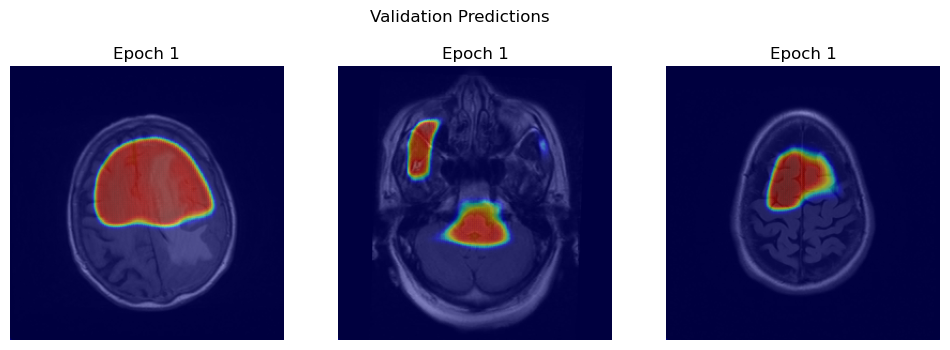

211/211 [==============================] - 102s 342ms/step - loss: 0.3928 - dice_coef: 0.0982 - iou_coef: 0.0530 - val_loss: 0.3801 - val_dice_coef: 0.1417 - val_iou_coef: 0.0821
Epoch 2/100
211/211 [==============================] - ETA: 0s - loss: 0.3200 - dice_coef: 0.1804 - iou_coef: 0.1013
Epoch 2: val_loss did not improve from 0.38014
1/1 [==============================] - 0s 25ms/step


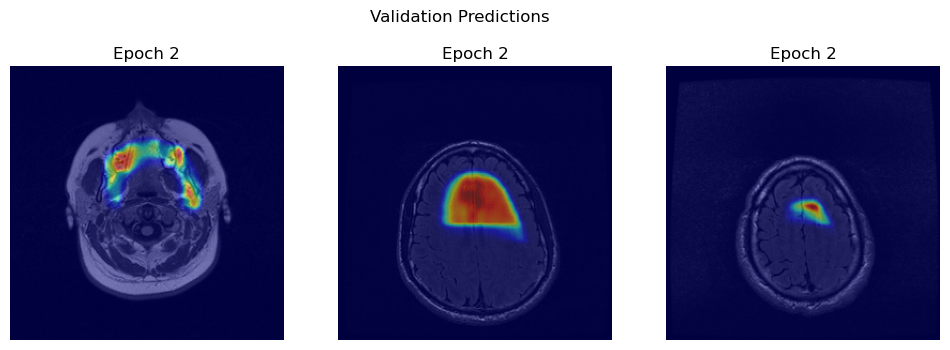

211/211 [==============================] - 47s 222ms/step - loss: 0.3200 - dice_coef: 0.1804 - iou_coef: 0.1013 - val_loss: 0.4011 - val_dice_coef: 0.1347 - val_iou_coef: 0.0780
Epoch 3/100
211/211 [==============================] - ETA: 0s - loss: 0.3078 - dice_coef: 0.2026 - iou_coef: 0.1160
Epoch 3: val_loss improved from 0.38014 to 0.37981, saving model to unet_best_weights.keras
1/1 [==============================] - 0s 25ms/step


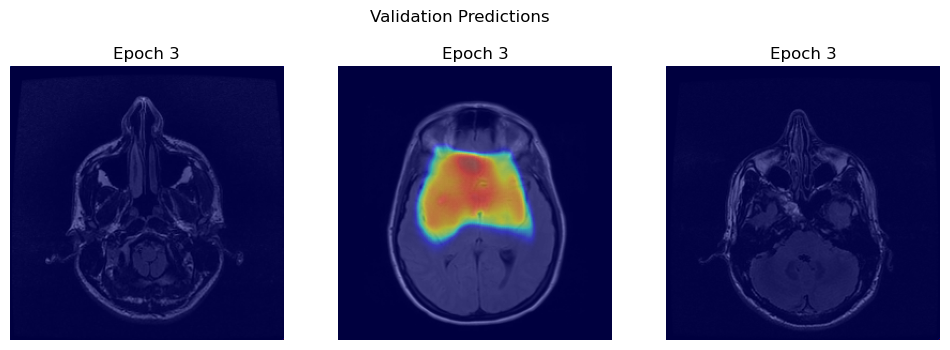

211/211 [==============================] - 51s 242ms/step - loss: 0.3078 - dice_coef: 0.2026 - iou_coef: 0.1160 - val_loss: 0.3798 - val_dice_coef: 0.1567 - val_iou_coef: 0.0924
Epoch 4/100
211/211 [==============================] - ETA: 0s - loss: 0.2835 - dice_coef: 0.2512 - iou_coef: 0.1491
Epoch 4: val_loss did not improve from 0.37981
1/1 [==============================] - 0s 24ms/step


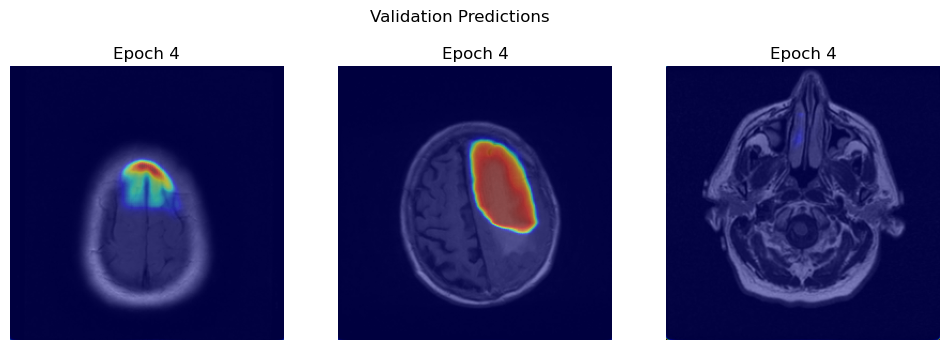

211/211 [==============================] - 47s 222ms/step - loss: 0.2835 - dice_coef: 0.2512 - iou_coef: 0.1491 - val_loss: 0.3944 - val_dice_coef: 0.1654 - val_iou_coef: 0.1026
Epoch 5/100
211/211 [==============================] - ETA: 0s - loss: 0.2552 - dice_coef: 0.3086 - iou_coef: 0.1893
Epoch 5: val_loss improved from 0.37981 to 0.32603, saving model to unet_best_weights.keras
1/1 [==============================] - 0s 24ms/step


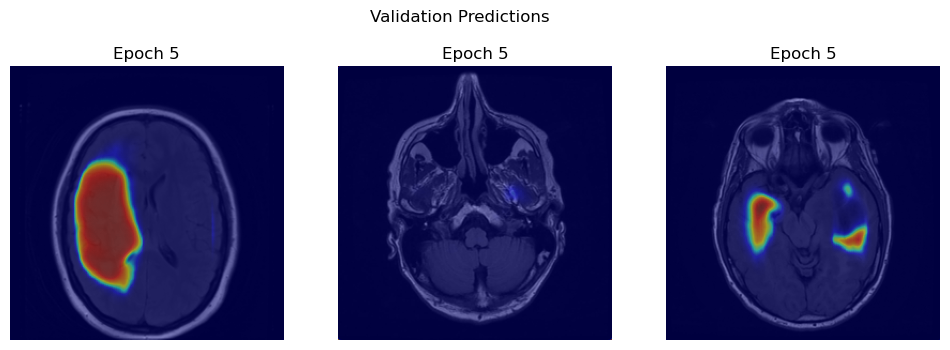

211/211 [==============================] - 51s 242ms/step - loss: 0.2552 - dice_coef: 0.3086 - iou_coef: 0.1893 - val_loss: 0.3260 - val_dice_coef: 0.2480 - val_iou_coef: 0.1609
Epoch 6/100
211/211 [==============================] - ETA: 0s - loss: 0.2276 - dice_coef: 0.3677 - iou_coef: 0.2342
Epoch 6: val_loss improved from 0.32603 to 0.31242, saving model to unet_best_weights.keras
1/1 [==============================] - 0s 27ms/step


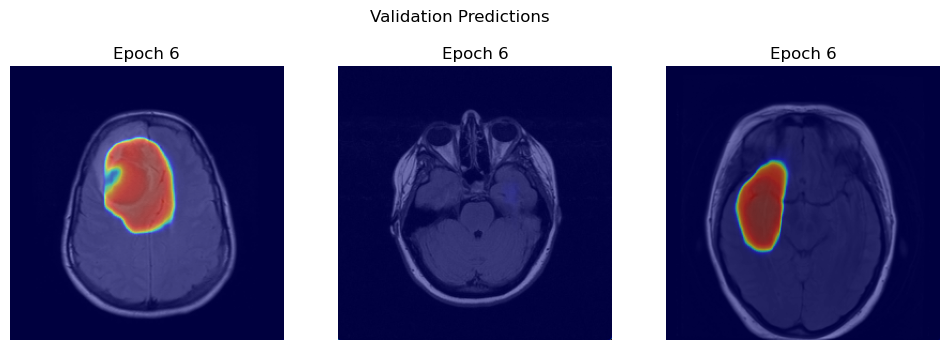

211/211 [==============================] - 51s 241ms/step - loss: 0.2276 - dice_coef: 0.3677 - iou_coef: 0.2342 - val_loss: 0.3124 - val_dice_coef: 0.2831 - val_iou_coef: 0.1895
Epoch 7/100
211/211 [==============================] - ETA: 0s - loss: 0.2082 - dice_coef: 0.4014 - iou_coef: 0.2591
Epoch 7: val_loss improved from 0.31242 to 0.29334, saving model to unet_best_weights.keras
1/1 [==============================] - 0s 29ms/step


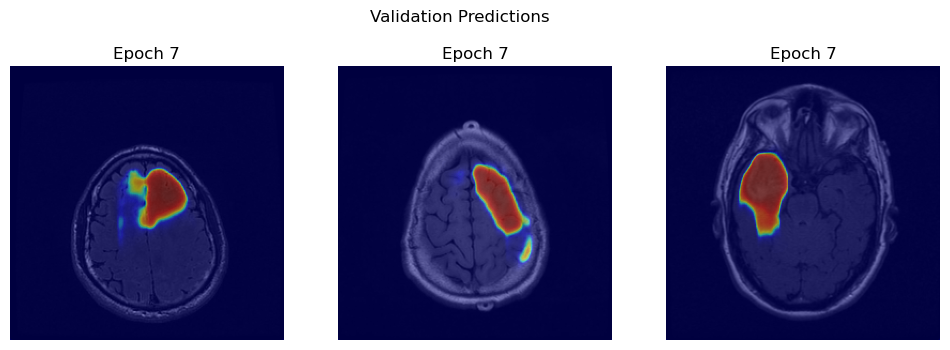

211/211 [==============================] - 52s 246ms/step - loss: 0.2082 - dice_coef: 0.4014 - iou_coef: 0.2591 - val_loss: 0.2933 - val_dice_coef: 0.2955 - val_iou_coef: 0.1963
Epoch 8/100
211/211 [==============================] - ETA: 0s - loss: 0.1991 - dice_coef: 0.4153 - iou_coef: 0.2717
Epoch 8: val_loss did not improve from 0.29334
1/1 [==============================] - 0s 24ms/step


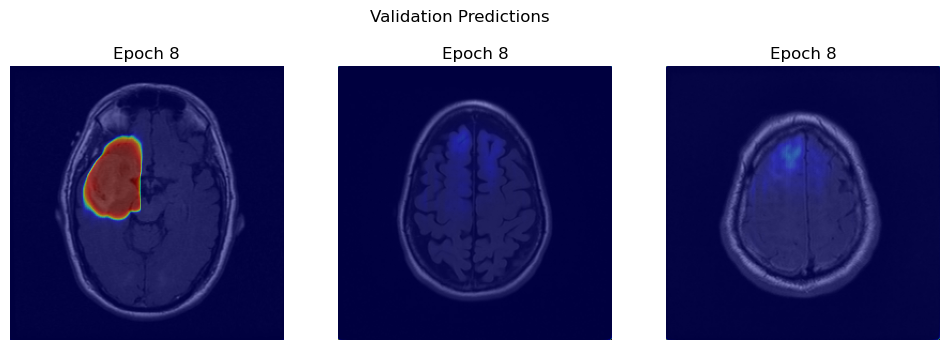

211/211 [==============================] - 47s 222ms/step - loss: 0.1991 - dice_coef: 0.4153 - iou_coef: 0.2717 - val_loss: 0.3136 - val_dice_coef: 0.2774 - val_iou_coef: 0.1870
Epoch 9/100
211/211 [==============================] - ETA: 0s - loss: 0.1618 - dice_coef: 0.5009 - iou_coef: 0.3450
Epoch 9: val_loss improved from 0.29334 to 0.29074, saving model to unet_best_weights.keras
1/1 [==============================] - 0s 24ms/step


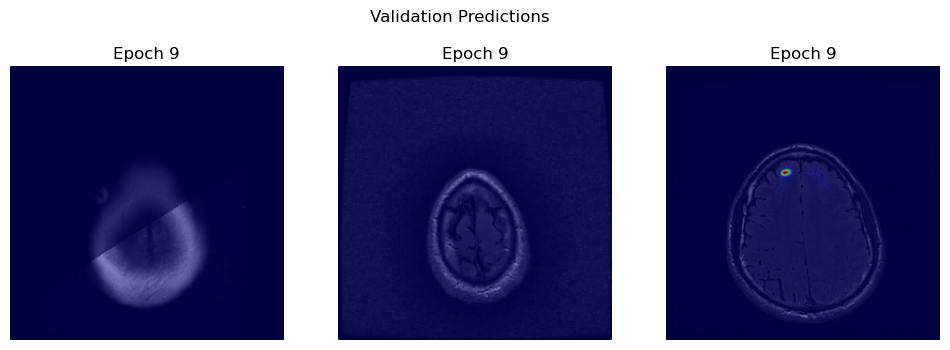

211/211 [==============================] - 51s 242ms/step - loss: 0.1618 - dice_coef: 0.5009 - iou_coef: 0.3450 - val_loss: 0.2907 - val_dice_coef: 0.3172 - val_iou_coef: 0.2187
Epoch 10/100
211/211 [==============================] - ETA: 0s - loss: 0.1595 - dice_coef: 0.5088 - iou_coef: 0.3533
Epoch 10: val_loss improved from 0.29074 to 0.28802, saving model to unet_best_weights.keras
1/1 [==============================] - 0s 27ms/step


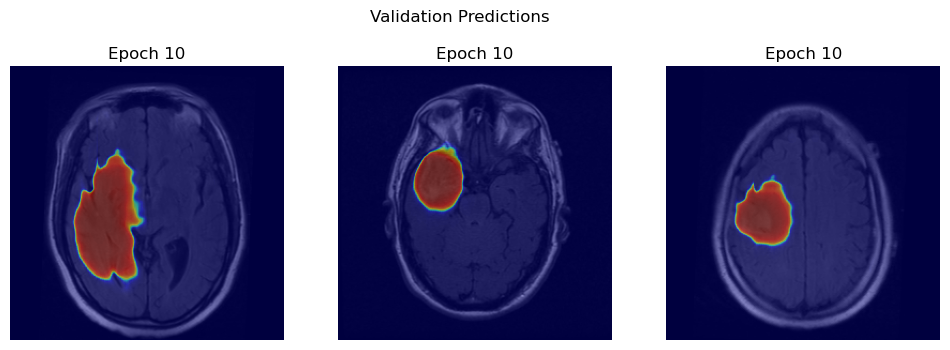

211/211 [==============================] - 51s 244ms/step - loss: 0.1595 - dice_coef: 0.5088 - iou_coef: 0.3533 - val_loss: 0.2880 - val_dice_coef: 0.2940 - val_iou_coef: 0.1940
Epoch 11/100
211/211 [==============================] - ETA: 0s - loss: 0.1483 - dice_coef: 0.5316 - iou_coef: 0.3731
Epoch 11: val_loss improved from 0.28802 to 0.26101, saving model to unet_best_weights.keras
1/1 [==============================] - 0s 28ms/step


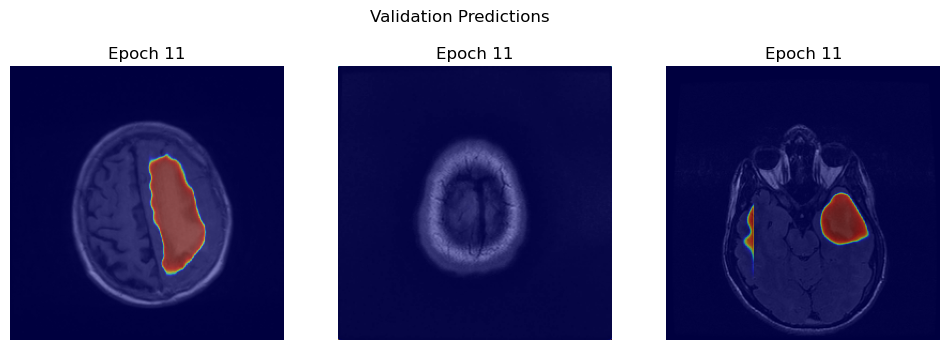

211/211 [==============================] - 51s 244ms/step - loss: 0.1483 - dice_coef: 0.5316 - iou_coef: 0.3731 - val_loss: 0.2610 - val_dice_coef: 0.3515 - val_iou_coef: 0.2411
Epoch 12/100
211/211 [==============================] - ETA: 0s - loss: 0.1367 - dice_coef: 0.5636 - iou_coef: 0.4039
Epoch 12: val_loss did not improve from 0.26101
1/1 [==============================] - 0s 27ms/step


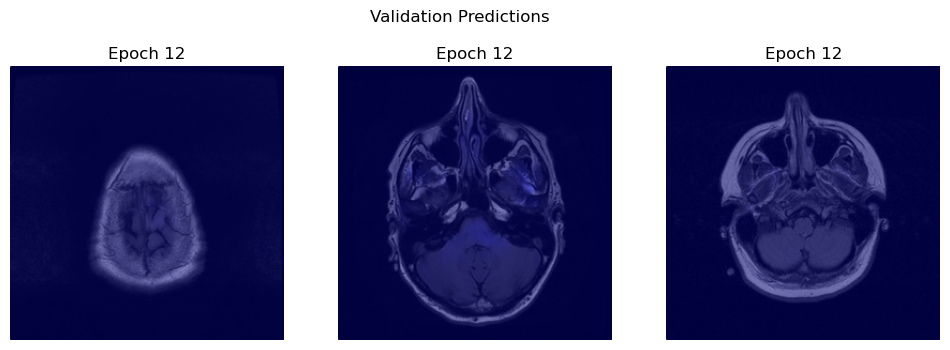

211/211 [==============================] - 47s 224ms/step - loss: 0.1367 - dice_coef: 0.5636 - iou_coef: 0.4039 - val_loss: 0.2909 - val_dice_coef: 0.3469 - val_iou_coef: 0.2493
Epoch 13/100
211/211 [==============================] - ETA: 0s - loss: 0.1283 - dice_coef: 0.5849 - iou_coef: 0.4253
Epoch 13: val_loss improved from 0.26101 to 0.25950, saving model to unet_best_weights.keras
1/1 [==============================] - 0s 45ms/step


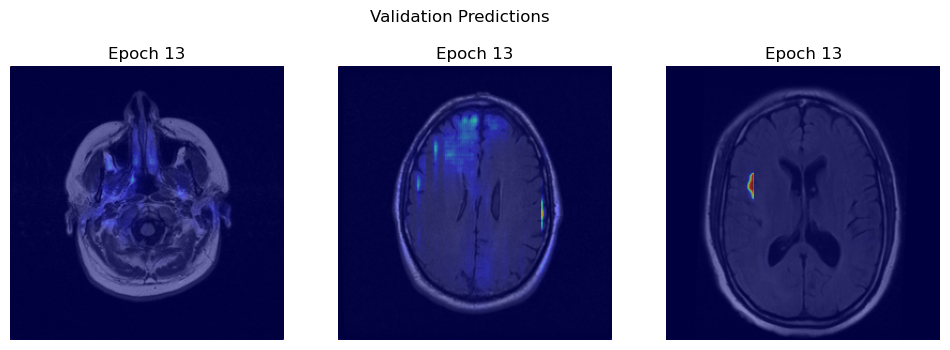

211/211 [==============================] - 52s 248ms/step - loss: 0.1283 - dice_coef: 0.5849 - iou_coef: 0.4253 - val_loss: 0.2595 - val_dice_coef: 0.3855 - val_iou_coef: 0.2713
Epoch 14/100
211/211 [==============================] - ETA: 0s - loss: 0.1407 - dice_coef: 0.5542 - iou_coef: 0.3968
Epoch 14: val_loss improved from 0.25950 to 0.25225, saving model to unet_best_weights.keras
1/1 [==============================] - 0s 26ms/step


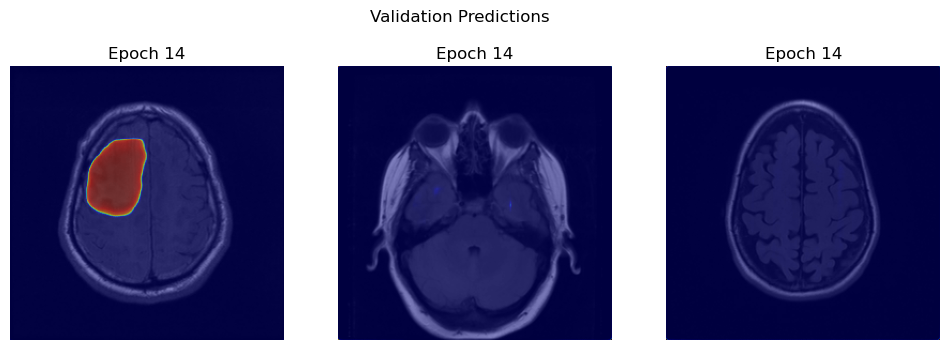

211/211 [==============================] - 51s 241ms/step - loss: 0.1407 - dice_coef: 0.5542 - iou_coef: 0.3968 - val_loss: 0.2522 - val_dice_coef: 0.3656 - val_iou_coef: 0.2515
Epoch 15/100
211/211 [==============================] - ETA: 0s - loss: 0.1369 - dice_coef: 0.5657 - iou_coef: 0.4079
Epoch 15: val_loss did not improve from 0.25225
1/1 [==============================] - 0s 26ms/step


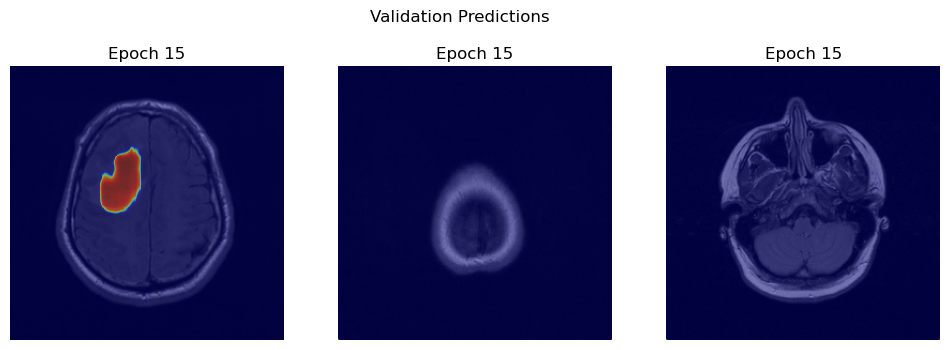

211/211 [==============================] - 47s 223ms/step - loss: 0.1369 - dice_coef: 0.5657 - iou_coef: 0.4079 - val_loss: 0.3326 - val_dice_coef: 0.2815 - val_iou_coef: 0.1878
Epoch 16/100
211/211 [==============================] - ETA: 0s - loss: 0.1387 - dice_coef: 0.5611 - iou_coef: 0.4043
Epoch 16: val_loss did not improve from 0.25225
1/1 [==============================] - 0s 33ms/step


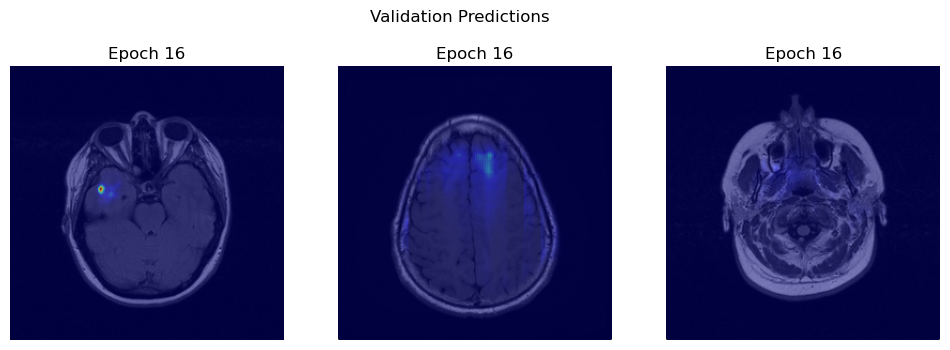

211/211 [==============================] - 47s 223ms/step - loss: 0.1387 - dice_coef: 0.5611 - iou_coef: 0.4043 - val_loss: 0.2528 - val_dice_coef: 0.3690 - val_iou_coef: 0.2540
Epoch 17/100
211/211 [==============================] - ETA: 0s - loss: 0.1339 - dice_coef: 0.5716 - iou_coef: 0.4179
Epoch 17: val_loss improved from 0.25225 to 0.25045, saving model to unet_best_weights.keras
1/1 [==============================] - 0s 25ms/step


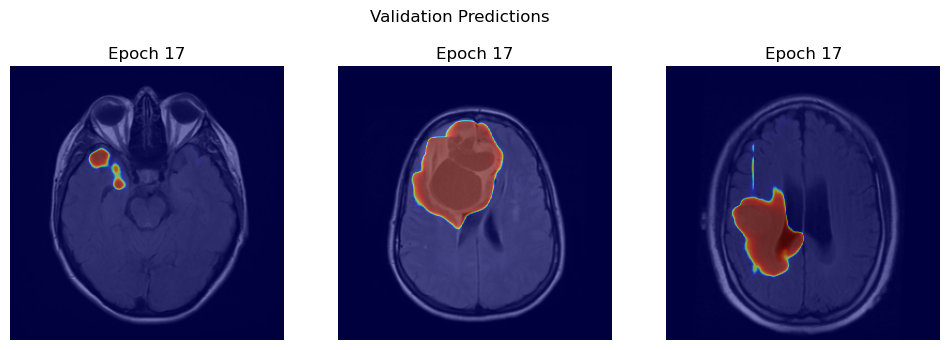

211/211 [==============================] - 52s 246ms/step - loss: 0.1339 - dice_coef: 0.5716 - iou_coef: 0.4179 - val_loss: 0.2505 - val_dice_coef: 0.3678 - val_iou_coef: 0.2584
Epoch 18/100
211/211 [==============================] - ETA: 0s - loss: 0.1118 - dice_coef: 0.6282 - iou_coef: 0.4725
Epoch 18: val_loss did not improve from 0.25045
1/1 [==============================] - 0s 29ms/step


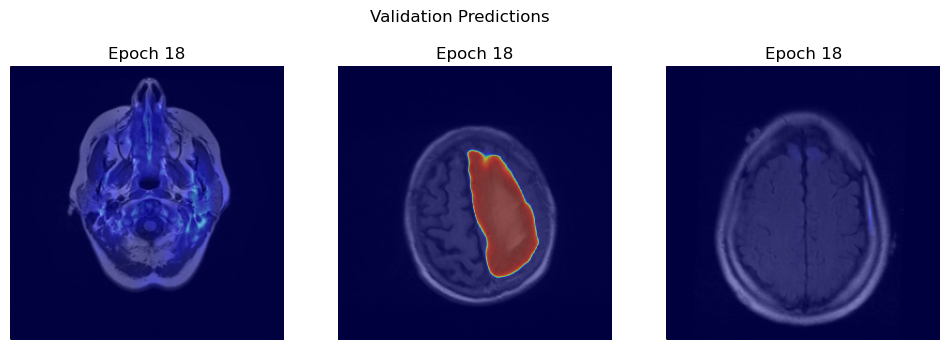

211/211 [==============================] - 47s 222ms/step - loss: 0.1118 - dice_coef: 0.6282 - iou_coef: 0.4725 - val_loss: 0.2639 - val_dice_coef: 0.3384 - val_iou_coef: 0.2289
Epoch 19/100
211/211 [==============================] - ETA: 0s - loss: 0.1224 - dice_coef: 0.5971 - iou_coef: 0.4402
Epoch 19: val_loss improved from 0.25045 to 0.25035, saving model to unet_best_weights.keras
1/1 [==============================] - 0s 28ms/step


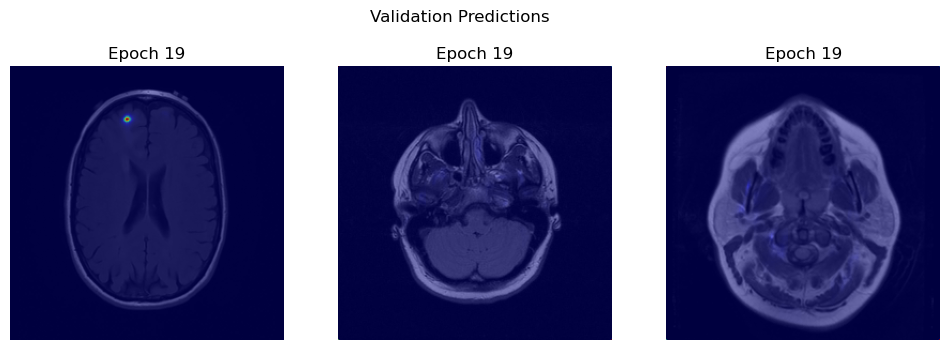

211/211 [==============================] - 52s 246ms/step - loss: 0.1224 - dice_coef: 0.5971 - iou_coef: 0.4402 - val_loss: 0.2503 - val_dice_coef: 0.3924 - val_iou_coef: 0.2781
Epoch 20/100
211/211 [==============================] - ETA: 0s - loss: 0.1091 - dice_coef: 0.6378 - iou_coef: 0.4818
Epoch 20: val_loss improved from 0.25035 to 0.24593, saving model to unet_best_weights.keras
1/1 [==============================] - 0s 25ms/step


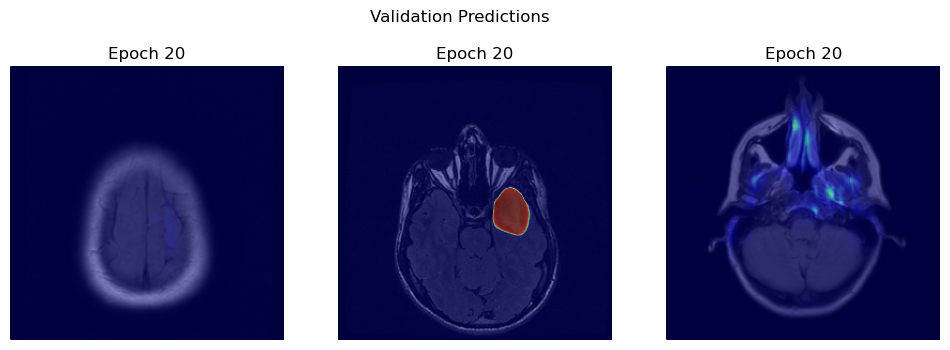

211/211 [==============================] - 51s 241ms/step - loss: 0.1091 - dice_coef: 0.6378 - iou_coef: 0.4818 - val_loss: 0.2459 - val_dice_coef: 0.3940 - val_iou_coef: 0.2812
Epoch 21/100
211/211 [==============================] - ETA: 0s - loss: 0.1176 - dice_coef: 0.6135 - iou_coef: 0.4592
Epoch 21: val_loss did not improve from 0.24593
1/1 [==============================] - 0s 26ms/step


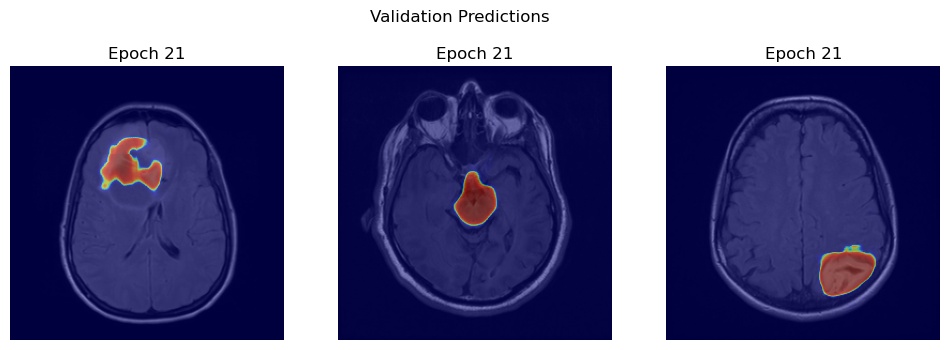

211/211 [==============================] - 47s 222ms/step - loss: 0.1176 - dice_coef: 0.6135 - iou_coef: 0.4592 - val_loss: 0.2527 - val_dice_coef: 0.3621 - val_iou_coef: 0.2523
Epoch 22/100
211/211 [==============================] - ETA: 0s - loss: 0.0991 - dice_coef: 0.6569 - iou_coef: 0.5001
Epoch 22: val_loss did not improve from 0.24593
1/1 [==============================] - 0s 25ms/step


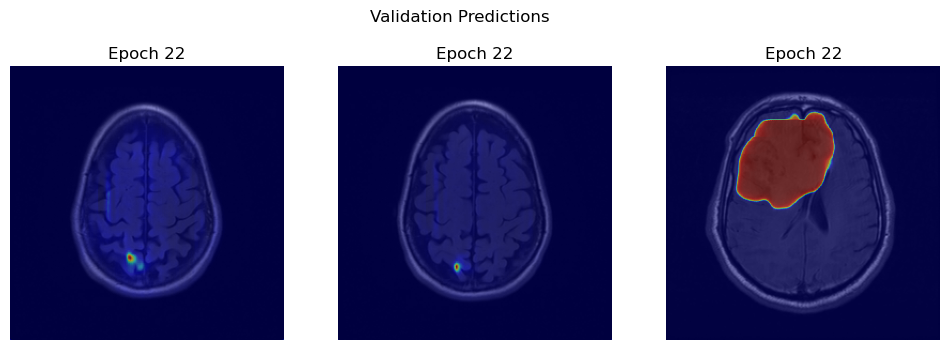

211/211 [==============================] - 47s 221ms/step - loss: 0.0991 - dice_coef: 0.6569 - iou_coef: 0.5001 - val_loss: 0.2502 - val_dice_coef: 0.3913 - val_iou_coef: 0.2792
Epoch 23/100
211/211 [==============================] - ETA: 0s - loss: 0.1066 - dice_coef: 0.6453 - iou_coef: 0.4925
Epoch 23: val_loss did not improve from 0.24593
1/1 [==============================] - 0s 26ms/step


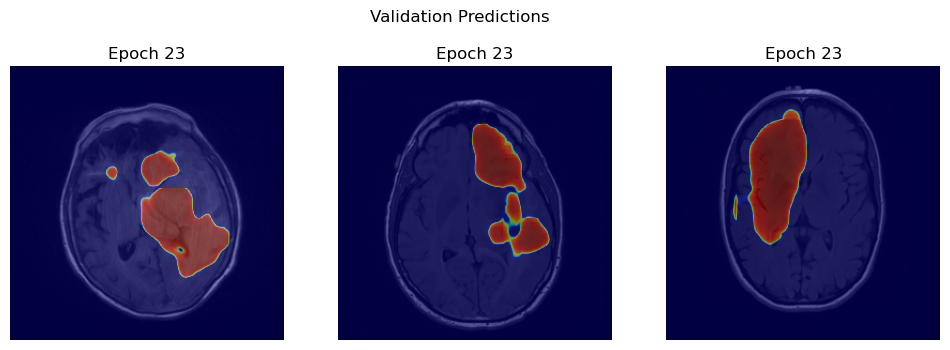

211/211 [==============================] - 47s 221ms/step - loss: 0.1066 - dice_coef: 0.6453 - iou_coef: 0.4925 - val_loss: 0.2850 - val_dice_coef: 0.2998 - val_iou_coef: 0.2015
Epoch 24/100
211/211 [==============================] - ETA: 0s - loss: 0.1029 - dice_coef: 0.6546 - iou_coef: 0.5019
Epoch 24: val_loss did not improve from 0.24593
1/1 [==============================] - 0s 26ms/step


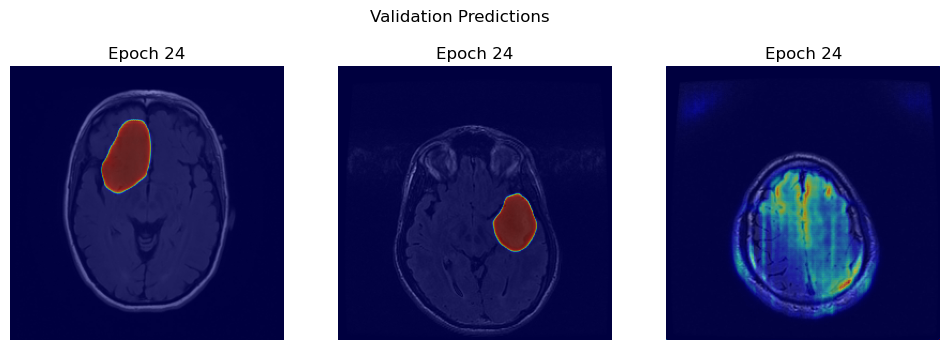

211/211 [==============================] - 47s 221ms/step - loss: 0.1029 - dice_coef: 0.6546 - iou_coef: 0.5019 - val_loss: 0.2624 - val_dice_coef: 0.3923 - val_iou_coef: 0.2798
Epoch 25/100
211/211 [==============================] - ETA: 0s - loss: 0.0890 - dice_coef: 0.6945 - iou_coef: 0.5449
Epoch 25: val_loss did not improve from 0.24593
1/1 [==============================] - 0s 24ms/step


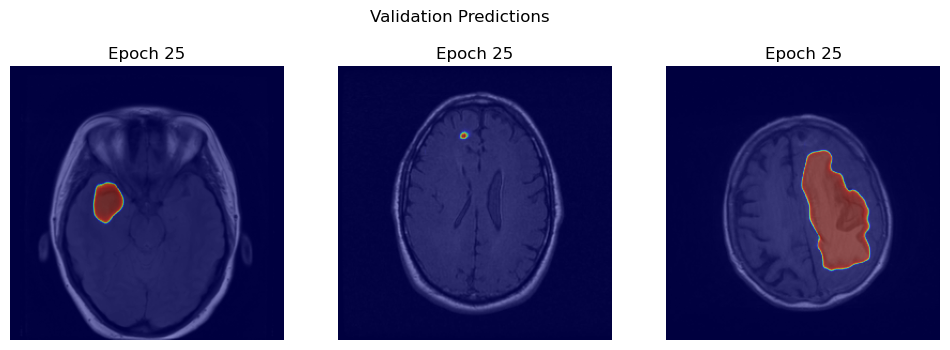

211/211 [==============================] - 47s 222ms/step - loss: 0.0890 - dice_coef: 0.6945 - iou_coef: 0.5449 - val_loss: 0.2522 - val_dice_coef: 0.3853 - val_iou_coef: 0.2770
Epoch 26/100
211/211 [==============================] - ETA: 0s - loss: 0.0919 - dice_coef: 0.6839 - iou_coef: 0.5338
Epoch 26: val_loss did not improve from 0.24593
1/1 [==============================] - 0s 24ms/step


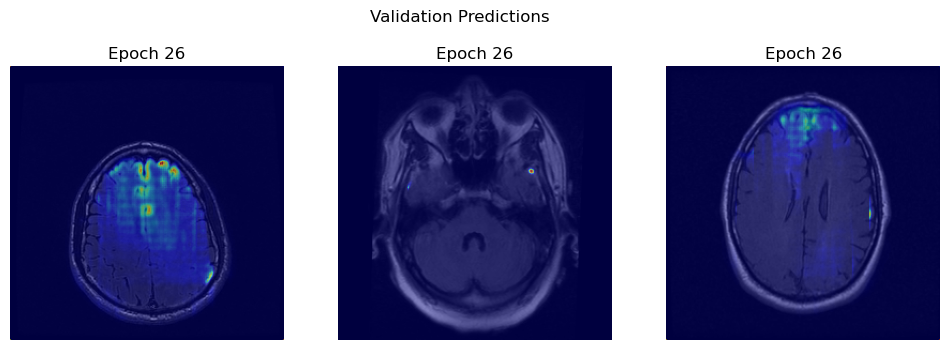

211/211 [==============================] - 47s 221ms/step - loss: 0.0919 - dice_coef: 0.6839 - iou_coef: 0.5338 - val_loss: 0.2611 - val_dice_coef: 0.3947 - val_iou_coef: 0.2845
Epoch 27/100
211/211 [==============================] - ETA: 0s - loss: 0.0905 - dice_coef: 0.6810 - iou_coef: 0.5293
Epoch 27: val_loss did not improve from 0.24593
1/1 [==============================] - 0s 26ms/step


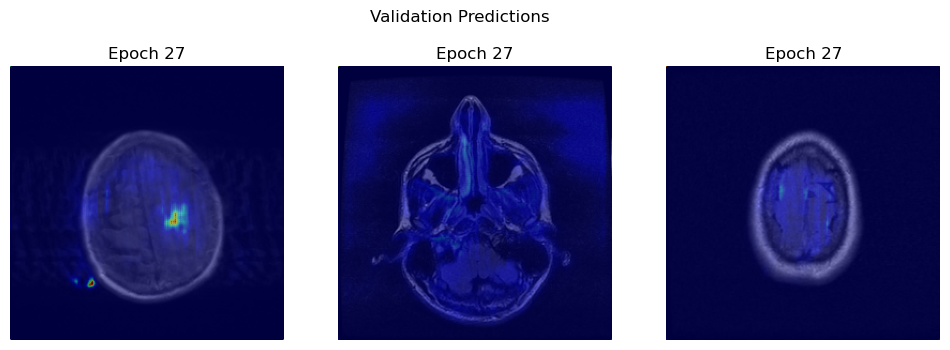

211/211 [==============================] - 47s 221ms/step - loss: 0.0905 - dice_coef: 0.6810 - iou_coef: 0.5293 - val_loss: 0.2824 - val_dice_coef: 0.3358 - val_iou_coef: 0.2332
Epoch 28/100
211/211 [==============================] - ETA: 0s - loss: 0.1062 - dice_coef: 0.6398 - iou_coef: 0.4850
Epoch 28: val_loss improved from 0.24593 to 0.24331, saving model to unet_best_weights.keras
1/1 [==============================] - 0s 27ms/step


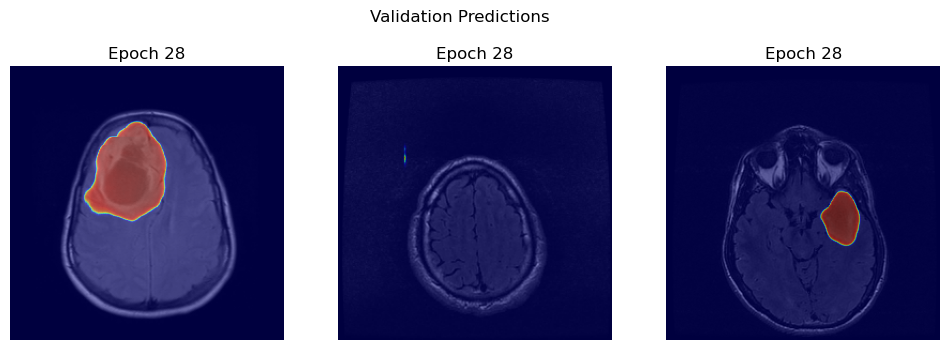

211/211 [==============================] - 51s 240ms/step - loss: 0.1062 - dice_coef: 0.6398 - iou_coef: 0.4850 - val_loss: 0.2433 - val_dice_coef: 0.4018 - val_iou_coef: 0.2888
Epoch 29/100
211/211 [==============================] - ETA: 0s - loss: 0.0930 - dice_coef: 0.6817 - iou_coef: 0.5298
Epoch 29: val_loss did not improve from 0.24331
1/1 [==============================] - 0s 26ms/step


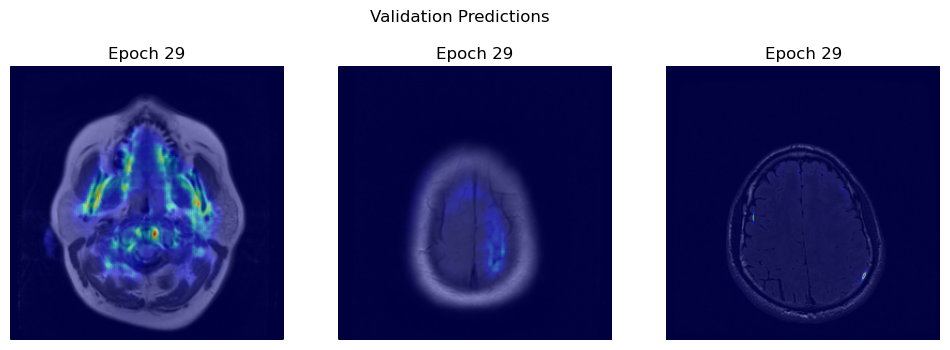

211/211 [==============================] - 47s 222ms/step - loss: 0.0930 - dice_coef: 0.6817 - iou_coef: 0.5298 - val_loss: 0.2454 - val_dice_coef: 0.3966 - val_iou_coef: 0.2813
Epoch 30/100
211/211 [==============================] - ETA: 0s - loss: 0.1012 - dice_coef: 0.6623 - iou_coef: 0.5118
Epoch 30: val_loss did not improve from 0.24331
1/1 [==============================] - 0s 25ms/step


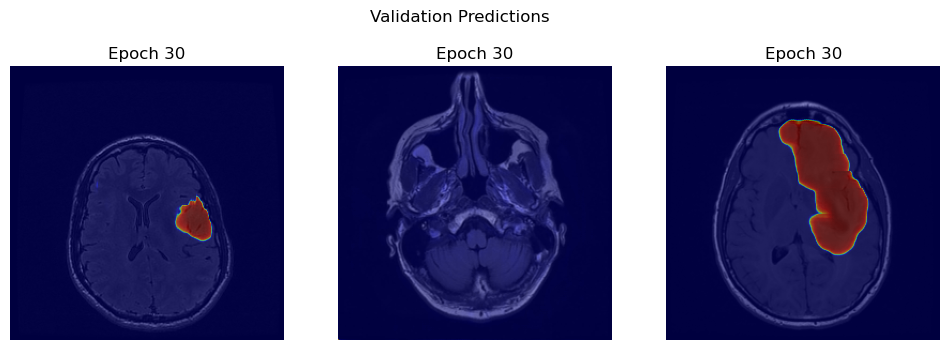

211/211 [==============================] - 47s 221ms/step - loss: 0.1012 - dice_coef: 0.6623 - iou_coef: 0.5118 - val_loss: 0.2669 - val_dice_coef: 0.3248 - val_iou_coef: 0.2198
Epoch 31/100
211/211 [==============================] - ETA: 0s - loss: 0.0987 - dice_coef: 0.6660 - iou_coef: 0.5132
Epoch 31: val_loss did not improve from 0.24331
1/1 [==============================] - 0s 27ms/step


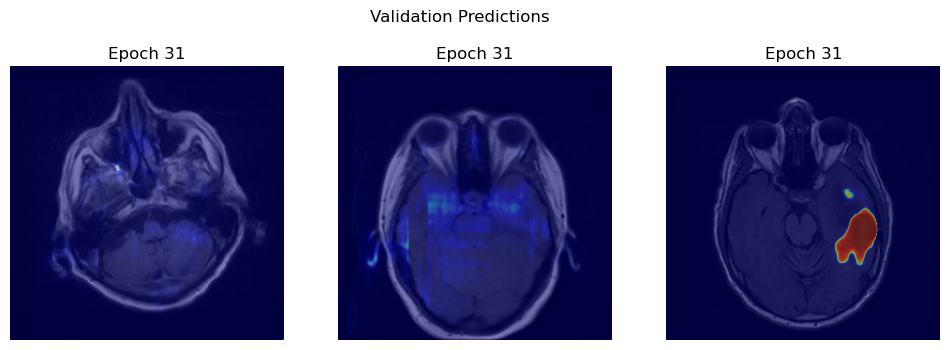

211/211 [==============================] - 47s 221ms/step - loss: 0.0987 - dice_coef: 0.6660 - iou_coef: 0.5132 - val_loss: 0.2561 - val_dice_coef: 0.3709 - val_iou_coef: 0.2644
Epoch 32/100
211/211 [==============================] - ETA: 0s - loss: 0.1015 - dice_coef: 0.6571 - iou_coef: 0.5048
Epoch 32: val_loss did not improve from 0.24331
1/1 [==============================] - 0s 24ms/step


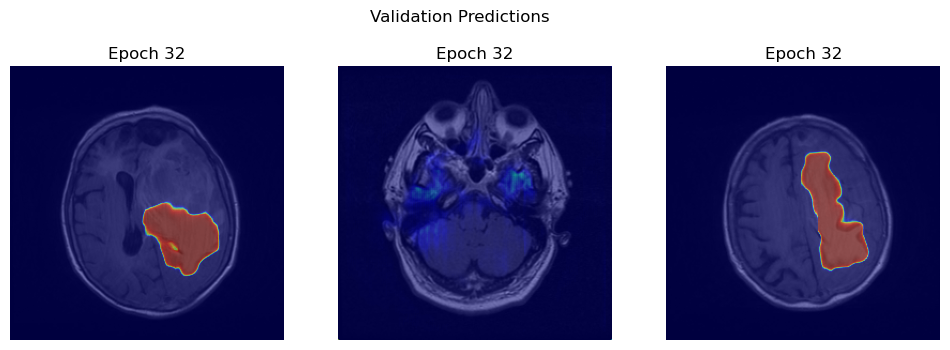

211/211 [==============================] - 47s 221ms/step - loss: 0.1015 - dice_coef: 0.6571 - iou_coef: 0.5048 - val_loss: 0.2888 - val_dice_coef: 0.3634 - val_iou_coef: 0.2572
Epoch 33/100
211/211 [==============================] - ETA: 0s - loss: 0.0972 - dice_coef: 0.6763 - iou_coef: 0.5276
Epoch 33: val_loss did not improve from 0.24331
1/1 [==============================] - 0s 25ms/step


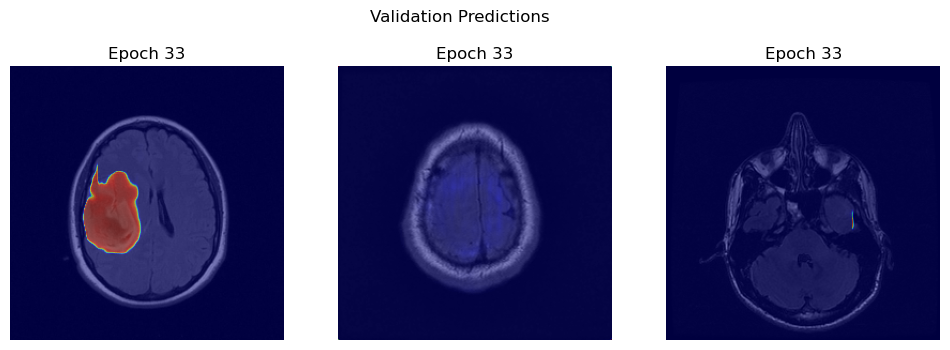

211/211 [==============================] - 46s 220ms/step - loss: 0.0972 - dice_coef: 0.6763 - iou_coef: 0.5276 - val_loss: 0.2574 - val_dice_coef: 0.3795 - val_iou_coef: 0.2676
Epoch 34/100
211/211 [==============================] - ETA: 0s - loss: 0.0987 - dice_coef: 0.6676 - iou_coef: 0.5170
Epoch 34: val_loss did not improve from 0.24331
1/1 [==============================] - 0s 30ms/step


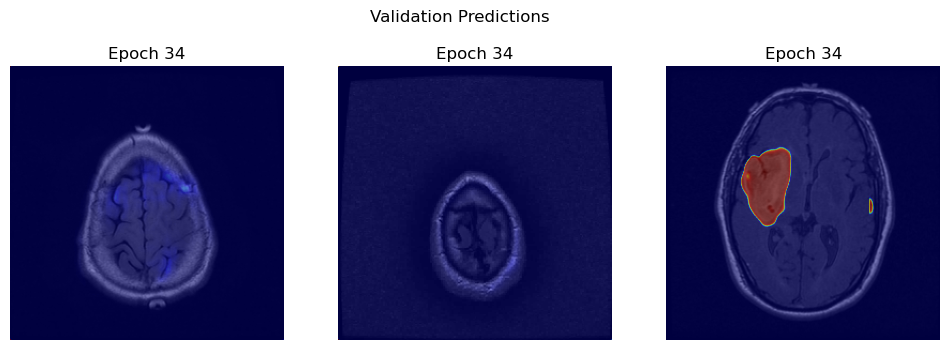

211/211 [==============================] - 47s 221ms/step - loss: 0.0987 - dice_coef: 0.6676 - iou_coef: 0.5170 - val_loss: 0.2478 - val_dice_coef: 0.4154 - val_iou_coef: 0.3050
Epoch 35/100
211/211 [==============================] - ETA: 0s - loss: 0.0865 - dice_coef: 0.7011 - iou_coef: 0.5560
Epoch 35: val_loss did not improve from 0.24331
1/1 [==============================] - 0s 26ms/step


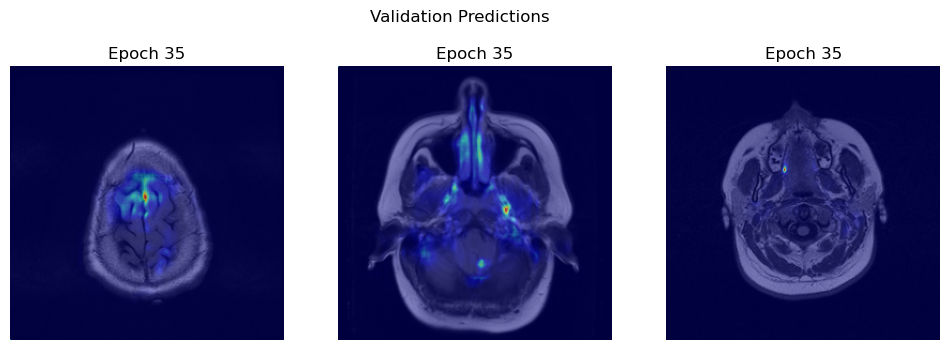

211/211 [==============================] - 47s 221ms/step - loss: 0.0865 - dice_coef: 0.7011 - iou_coef: 0.5560 - val_loss: 0.2449 - val_dice_coef: 0.4211 - val_iou_coef: 0.3111
Epoch 36/100
211/211 [==============================] - ETA: 0s - loss: 0.0860 - dice_coef: 0.7011 - iou_coef: 0.5524
Epoch 36: val_loss did not improve from 0.24331
1/1 [==============================] - 0s 25ms/step


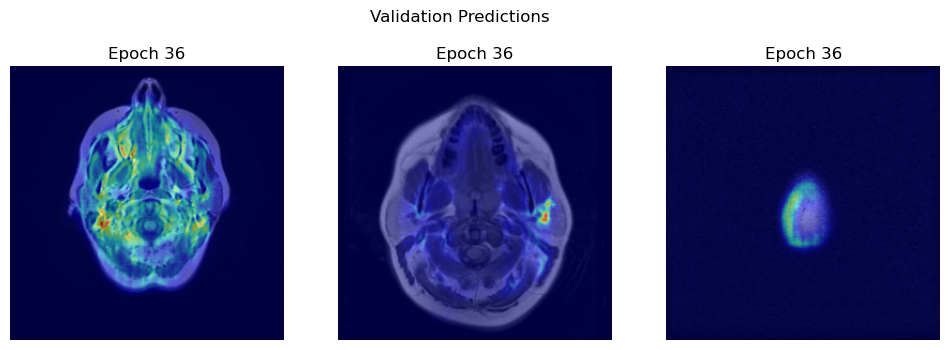

211/211 [==============================] - 47s 221ms/step - loss: 0.0860 - dice_coef: 0.7011 - iou_coef: 0.5524 - val_loss: 0.2604 - val_dice_coef: 0.3642 - val_iou_coef: 0.2573
Epoch 37/100
211/211 [==============================] - ETA: 0s - loss: 0.0811 - dice_coef: 0.7133 - iou_coef: 0.5655
Epoch 37: val_loss did not improve from 0.24331
1/1 [==============================] - 0s 25ms/step


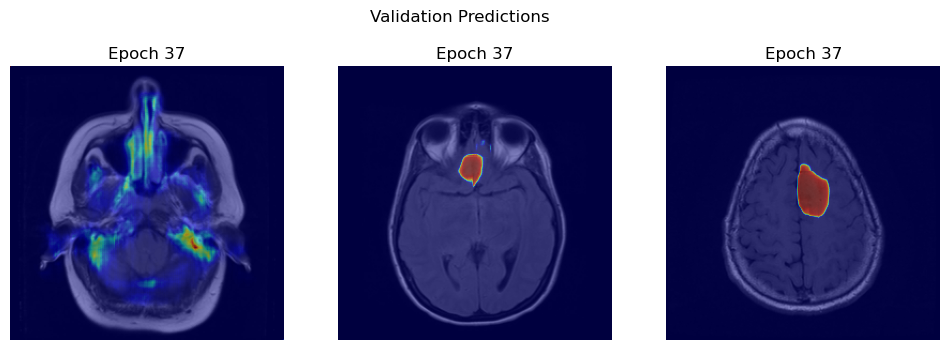

211/211 [==============================] - 46s 220ms/step - loss: 0.0811 - dice_coef: 0.7133 - iou_coef: 0.5655 - val_loss: 0.2510 - val_dice_coef: 0.4056 - val_iou_coef: 0.2925
Epoch 38/100
211/211 [==============================] - ETA: 0s - loss: 0.0789 - dice_coef: 0.7205 - iou_coef: 0.5754Restoring model weights from the end of the best epoch: 28.

Epoch 38: val_loss did not improve from 0.24331
1/1 [==============================] - 0s 27ms/step


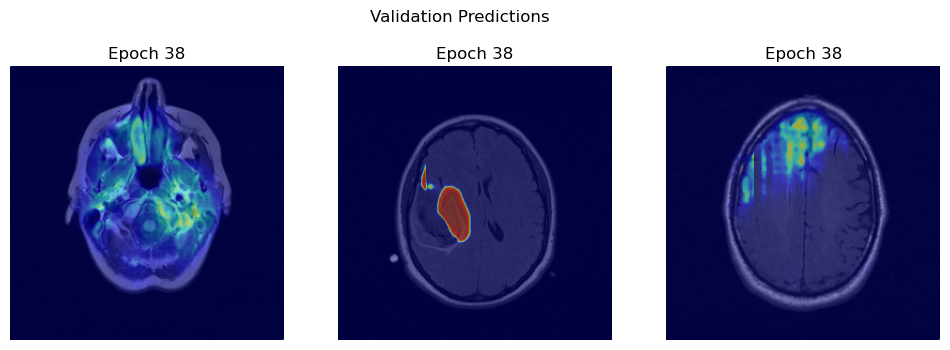

211/211 [==============================] - 47s 221ms/step - loss: 0.0789 - dice_coef: 0.7205 - iou_coef: 0.5754 - val_loss: 0.2493 - val_dice_coef: 0.3935 - val_iou_coef: 0.2834
Epoch 38: early stopping


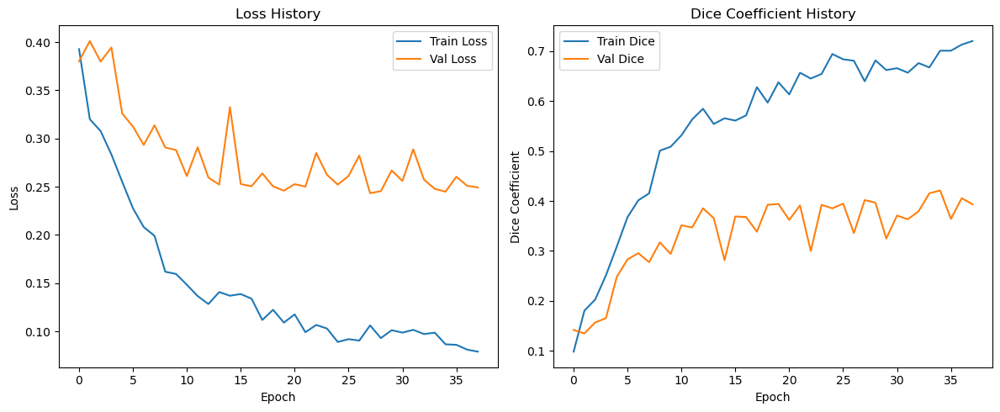

In [15]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random
import tensorflow as tf
from tensorflow.keras import layers, models, backend as K
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, Callback


def load_data(indices, use_normalized=True):
    X = []
    Y = []
    for idx in indices:
        if use_normalized:
            img = normalized_images[idx]
        else:
            img = cv2.imread(image_files[idx], cv2.IMREAD_GRAYSCALE).astype(np.float32)/255.0
        img = np.expand_dims(img, axis=-1)
        X.append(img)
        mask = cv2.imread(mask_files[idx], cv2.IMREAD_GRAYSCALE)
        mask = (mask/255.0).astype(np.float32)
        mask = np.expand_dims(mask, axis=-1)
        Y.append(mask)
    return np.array(X), np.array(Y)

X_train_orig, Y_train_orig = load_data(train_indices, use_normalized=True)
X_val, Y_val = load_data(val_indices, use_normalized=True)
X_test, Y_test = load_data(test_indices, use_normalized=True)


aug_X = []
aug_Y = []
for pid in augmented_train_data:
    for (aug_img, aug_mask) in augmented_train_data[pid]:
        aug_img_norm = aug_img.astype(np.float32)/255.0
        aug_img_norm = np.expand_dims(aug_img_norm, axis=-1)
        aug_X.append(aug_img_norm)
        aug_mask_bin = (aug_mask/255.0).astype(np.float32)
        aug_mask_bin = np.expand_dims(aug_mask_bin, axis=-1)
        aug_Y.append(aug_mask_bin)
        
X_train = np.concatenate([X_train_orig, np.array(aug_X)], axis=0)
Y_train = np.concatenate([Y_train_orig, np.array(aug_Y)], axis=0)

print("Training set shape:", X_train.shape, Y_train.shape)
print("Validation set shape:", X_val.shape, Y_val.shape)
print("Test set shape:", X_test.shape, Y_test.shape)


def unet_model(input_shape=(256,256,1)):
    inputs = layers.Input(input_shape)
    
    # Encoder
    c1 = layers.Conv2D(64, (3,3), activation='relu', padding='same')(inputs)
    c1 = layers.Conv2D(64, (3,3), activation='relu', padding='same')(c1)
    p1 = layers.MaxPooling2D((2,2))(c1)
    
    c2 = layers.Conv2D(128, (3,3), activation='relu', padding='same')(p1)
    c2 = layers.Conv2D(128, (3,3), activation='relu', padding='same')(c2)
    p2 = layers.MaxPooling2D((2,2))(c2)
    
    c3 = layers.Conv2D(256, (3,3), activation='relu', padding='same')(p2)
    c3 = layers.Conv2D(256, (3,3), activation='relu', padding='same')(c3)
    p3 = layers.MaxPooling2D((2,2))(c3)
    
    c4 = layers.Conv2D(512, (3,3), activation='relu', padding='same')(p3)
    c4 = layers.Conv2D(512, (3,3), activation='relu', padding='same')(c4)
    p4 = layers.MaxPooling2D((2,2))(c4)
    
    # Bottleneck
    c5 = layers.Conv2D(1024, (3,3), activation='relu', padding='same')(p4)
    c5 = layers.Conv2D(1024, (3,3), activation='relu', padding='same')(c5)
    
    # Decoder
    u6 = layers.Conv2DTranspose(512, (2,2), strides=(2,2), padding='same')(c5)
    u6 = layers.concatenate([u6, c4])
    c6 = layers.Conv2D(512, (3,3), activation='relu', padding='same')(u6)
    c6 = layers.Conv2D(512, (3,3), activation='relu', padding='same')(c6)
    
    u7 = layers.Conv2DTranspose(256, (2,2), strides=(2,2), padding='same')(c6)
    u7 = layers.concatenate([u7, c3])
    c7 = layers.Conv2D(256, (3,3), activation='relu', padding='same')(u7)
    c7 = layers.Conv2D(256, (3,3), activation='relu', padding='same')(c7)
    
    u8 = layers.Conv2DTranspose(128, (2,2), strides=(2,2), padding='same')(c7)
    u8 = layers.concatenate([u8, c2])
    c8 = layers.Conv2D(128, (3,3), activation='relu', padding='same')(u8)
    c8 = layers.Conv2D(128, (3,3), activation='relu', padding='same')(c8)
    
    u9 = layers.Conv2DTranspose(64, (2,2), strides=(2,2), padding='same')(c8)
    u9 = layers.concatenate([u9, c1])
    c9 = layers.Conv2D(64, (3,3), activation='relu', padding='same')(u9)
    c9 = layers.Conv2D(64, (3,3), activation='relu', padding='same')(c9)
    
    outputs = layers.Conv2D(1, (1,1), activation='sigmoid')(c9)
    
    model = models.Model(inputs=[inputs], outputs=[outputs])
    return model

model = unet_model(input_shape=(256,256,1))
model.summary()


smooth = 1e-6

def weighted_dice_loss(y_true, y_pred):
   
    weight_factor =
    weights = 1 + (weight_factor - 1) * y_true 
    
    intersection = K.sum(weights * y_true * y_pred)
    summation = K.sum(weights * (y_true + y_pred))
    dice = (2. * intersection + smooth) / (summation + smooth)
    return 1 - dice

def focal_loss(y_true, y_pred, gamma=2., alpha=0.25):
    y_true = K.cast(y_true, tf.float32)
    y_pred = K.clip(y_pred, K.epsilon(), 1.0 - K.epsilon())
    loss = -alpha * K.pow(1 - y_pred, gamma) * y_true * K.log(y_pred) - \
           (1 - alpha) * K.pow(y_pred, gamma) * (1 - y_true) * K.log(1 - y_pred)
    return K.mean(loss)

def combined_loss(y_true, y_pred):
    return 0.5 * weighted_dice_loss(y_true, y_pred) + 0.5 * focal_loss(y_true, y_pred)

def dice_coef(y_true, y_pred):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)

def iou_coef(y_true, y_pred):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    union = K.sum(y_true_f) + K.sum(y_pred_f) - intersection
    return (intersection + smooth) / (union + smooth)

class DisplayCallback(Callback):
    def on_epoch_end(self, epoch, logs=None):
        sample_idx = np.random.choice(len(X_val), 3, replace=False)
        plt.figure(figsize=(12,4))
        for i, idx in enumerate(sample_idx):
            img = X_val[idx]
            true_mask = Y_val[idx]
            pred_mask = self.model.predict(np.expand_dims(img, axis=0))[0]
            plt.subplot(1,3,i+1)
            plt.imshow(img.squeeze(), cmap='gray')
            plt.imshow(pred_mask.squeeze(), alpha=0.5, cmap='jet')
            plt.title(f"Epoch {epoch+1}")
            plt.axis('off')
        plt.suptitle("Validation Predictions")
        plt.show()


model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
              loss=combined_loss,
              metrics=[dice_coef, iou_coef])


earlystop = EarlyStopping(monitor='val_loss', patience=10, verbose=1, restore_best_weights=True)
checkpoint = ModelCheckpoint('unet_best_weights.keras', monitor='val_loss', verbose=1, save_best_only=True)
display_cb = DisplayCallback()

history = model.fit(X_train, Y_train,
                    validation_data=(X_val, Y_val),
                    batch_size=16,
                    epochs=100,
                    callbacks=[earlystop, checkpoint, display_cb])


plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss History")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['dice_coef'], label='Train Dice')
plt.plot(history.history['val_dice_coef'], label='Val Dice')
plt.xlabel("Epoch")
plt.ylabel("Dice Coefficient")
plt.title("Dice Coefficient History")
plt.legend()

plt.tight_layout()
plt.show()
